# Actividad 2. Análisis Estadístico de Datos y Creación de Gráficos Básicos

**Proyecto integrador:** fase 1, planteamiento, descripción del dataset y análisis exploratorio  
**Autor:** Julián Andrés Lasso Figueroa  
**Correo institucional:** jlasso96@unisalle.edu.co  
**Programa:** Maestría en Inteligencia Artificial, Universidad de La Salle  
**Asignatura:** Ciencia de Datos, Unidad 1, principios de visualización  
**Docente:** Fabián Camilo Castro Riveros  
**Fecha:** noviembre de 2026

---

## 0. Planteamiento y configuración

### 0.1. Contexto

El Saber 11 es la evaluación estandarizada que el Instituto Colombiano para la Evaluación de la Educación (ICFES) aplica a quienes terminan la educación media, y sus resultados individuales están publicados en el portal de datos abiertos del Estado colombiano. Junto con el puntaje, cada registro trae lo que el estudiante declara sobre su hogar (estrato, educación de los padres, bienes y conectividad) y lo que el ICFES sabe de su colegio (naturaleza, zona, jornada y departamento). Para una secretaría de educación o un colegio, saber cuánto del puntaje se explica por condiciones que la escuela no controla, y cuánto por condiciones del colegio, cambia la forma de asignar recursos: no es lo mismo reforzar la conectividad de los hogares que intervenir la jornada o la zona de las sedes.

Este cuaderno es el respaldo del entregable 1 del proyecto integrador: describe el conjunto de datos, documenta su calidad y hace el análisis exploratorio que sostiene las preguntas de las fases siguientes. Cada cifra que cita el informe sale de una salida de este cuaderno y se exporta a `resultados/cifras-fase-1.tex`.

### 0.2. Preguntas de investigación

- **Principal.** ¿En qué medida las condiciones socioeconómicas del hogar (estrato, educación de los padres, internet y computador) y las características del colegio (naturaleza, zona, jornada) explican y permiten anticipar el puntaje global del Saber 11 de 2022-2?
- **S1 (regresión).** ¿Cuánto del puntaje global explican esas variables, sin usar los puntajes por área ni el de inglés?
- **S2 (clasificación).** ¿Qué tan separables son los perfiles de los estudiantes de colegios oficiales y no oficiales a partir de su hogar?
- **S3 (segmentación).** ¿Qué perfiles de desempeño por área existen y cómo se reparten por estrato, zona y naturaleza del colegio?

### 0.3. Objetivos

- **General.** Determinar, a más tardar el 27 de noviembre de 2026, en qué medida las condiciones del hogar y del colegio explican y permiten anticipar el puntaje global de los estudiantes con resultado publicado en el Saber 11 de 2022-2, con modelos de regresión, clasificación y segmentación evaluados sobre un conjunto de prueba independiente y comunicados en un tablero interactivo.
- **E1.** Estimar, a más tardar el 14 de noviembre de 2026, la proporción de la varianza del puntaje global que explican las variables del hogar y del colegio, sin los puntajes por área ni el de inglés, comparando un modelo base con una regresión regularizada y un ensamble por R², RMSE y MAE en validación y en prueba.
- **E2.** Medir, a más tardar el 14 de noviembre de 2026, qué tan separables son los estudiantes de colegios oficiales y no oficiales a partir de su hogar, con dos clasificadores evaluados por F1 y AUC-ROC frente a un clasificador base que predice siempre la clase mayoritaria.
- **E3.** Identificar, a más tardar el 14 de noviembre de 2026, perfiles de desempeño en las cinco áreas con K-Means y con agrupamiento jerárquico de Ward, eligiendo el número de grupos por el codo y la silueta, y describir su composición por estrato, zona y naturaleza del colegio.

### 0.4. Entorno

El cuaderno corre con el entorno del repositorio (`uv sync`, o `pip install -r requirements.txt` seguido de `pip install -e . --no-deps` para instalar el paquete del proyecto) y usa el paquete `saber11` para las rutas, las constantes del dataset y el registro de cifras. Las versiones quedan impresas para que cualquier diferencia futura se pueda rastrear.

In [1]:
import ast
import inspect
import json
import platform
import re
import statistics
import tempfile
import textwrap
import time
import unicodedata
from collections.abc import Callable
from importlib.metadata import metadata, version
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import polars as pl
import seaborn as sns
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter
from scipy import stats

from saber11 import datos
from saber11.cifras import Cifras, en_espanol
from saber11.diccionario import COLUMNAS_EXCLUIDAS, VARIABLES

print(f"{'Python':<12}{platform.python_version()}")
for paquete in ("pandas", "polars", "numpy", "scipy", "matplotlib", "seaborn", "plotly", "kaleido"):
    print(f"{paquete:<12}{version(paquete)}")

Python      3.13.15
pandas      3.1.1
polars      2.1.0
numpy       2.5.4
scipy       1.18.1
matplotlib  3.11.2
seaborn     0.13.2
plotly      7.1.0
kaleido     1.5.0


### 0.5. Estilo gráfico, rutas y comprobaciones

Las figuras siguen la estética sobria de la actividad 1: fondo blanco, rejilla mínima, tipografía con serifa y la paleta categórica de Okabe e Ito, que también distinguen las personas con daltonismo. Se muestran a 110 puntos por pulgada y se guardan en PNG a 300. Todas las rutas parten de la raíz del repositorio, porque `nbconvert` ejecuta el cuaderno desde `notebooks/`, y se imprimen relativas a esa raíz. La función `comprobar` detiene el cuaderno si una condición falla y lleva la cuenta de las superadas.

In [2]:
PALETA_CATEGORICA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#4C4C4C"]
COLOR_PRINCIPAL = "#2C4A6E"
COLOR_APOYO = "#7F7F7F"
COLOR_OFICIAL, COLOR_NO_OFICIAL = PALETA_CATEGORICA[0], PALETA_CATEGORICA[1]

mpl.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "font.family": "DejaVu Serif",
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.edgecolor": "#4C4C4C",
        "axes.linewidth": 0.7,
        "grid.color": "#D9D9D9",
        "grid.linewidth": 0.5,
        "legend.frameon": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.prop_cycle": mpl.cycler(color=PALETA_CATEGORICA),
    }
)

RAIZ = datos.RAIZ_PROYECTO
RUTA_FIGURAS = RAIZ / "figuras" / "fase-1"
RUTA_RESULTADOS = RAIZ / "resultados"
RUTA_AGREGADOS = RAIZ / "data" / "agregados"
RUTA_PARIDAD_R = RUTA_RESULTADOS / "r" / "fase-1.json"
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
FIGURAS_ESCRITAS: list[Path] = []
COMPROBACIONES: list[str] = []
FORMATO_MILES = FuncFormatter(lambda valor, _: en_espanol(valor))


def relativa(ruta: Path) -> str:
    """Ruta relativa a la raíz del repositorio, para no imprimir rutas locales."""
    return ruta.relative_to(RAIZ).as_posix()


def guardar_figura(figura: plt.Figure, nombre: str) -> Path:
    """Escribe la figura en `figuras/fase-1/` como PNG y la registra para la comprobación final."""
    ruta = RUTA_FIGURAS / f"{nombre}.png"
    figura.savefig(ruta)
    FIGURAS_ESCRITAS.append(ruta)
    return ruta


def comprobar(descripcion: str, condicion: bool) -> None:
    """Detiene el cuaderno si la condición falla y lleva la cuenta de las superadas."""
    assert condicion, f"Comprobación fallida: {descripcion}"
    COMPROBACIONES.append(descripcion)
    print(f"[ok] {descripcion}")


def anotar_fuente(eje: plt.Axes, texto: str) -> None:
    """Escribe la fuente de los datos al pie de la figura, debajo del título del eje horizontal."""
    eje.annotate(
        texto,
        xy=(0.0, 0.0),
        xycoords=("figure fraction", eje.xaxis.label),
        xytext=(0, -6),
        textcoords="offset points",
        fontsize=7,
        color="#4C4C4C",
        ha="left",
        va="top",
    )


def nombre_macro(columna: str) -> str:
    """Convierte un nombre de columna en un sufijo de macro de LaTeX (solo letras)."""
    return "".join(parte.capitalize() for parte in columna.lower().split("_"))


cifras = Cifras()
cifra = cifras.cifra

### 0.6. Etiquetas comunes

El periodo del ICFES se escribe como año y semestre de aplicación (20224 es 2022-2). Las macros de LaTeX no admiten dígitos, así que cada periodo y cada puntaje tiene además un sufijo en letras.

In [3]:
PERIODO_ACTUAL = datos.PERIODO_MODELADO
ETIQUETA_PERIODO = {20142: "2014-2", 20152: "2015-2", 20162: "2016-2", 20172: "2017-2", 20194: "2019-2", 20224: "2022-2"}
ANIO_PERIODO = {periodo: int(etiqueta[:4]) for periodo, etiqueta in ETIQUETA_PERIODO.items()}
SUFIJO_PERIODO = {20142: "Catorce", 20152: "Quince", 20162: "Dieciseis", 20172: "Diecisiete", 20194: "Diecinueve", 20224: "Veintidos"}
NOMBRE_PUNTAJE = {
    "PUNT_GLOBAL": "Global",
    "PUNT_LECTURA_CRITICA": "Lectura crítica",
    "PUNT_MATEMATICAS": "Matemáticas",
    "PUNT_C_NATURALES": "Ciencias naturales",
    "PUNT_SOCIALES_CIUDADANAS": "Sociales y ciudadanas",
    "PUNT_INGLES": "Inglés",
}
SUFIJO_PUNTAJE = {
    "PUNT_GLOBAL": "Global",
    "PUNT_LECTURA_CRITICA": "Lectura",
    "PUNT_MATEMATICAS": "Matematicas",
    "PUNT_C_NATURALES": "Naturales",
    "PUNT_SOCIALES_CIUDADANAS": "Sociales",
    "PUNT_INGLES": "Ingles",
}
PUNTAJES = list(datos.PUNTAJES)
AREAS = PUNTAJES[1:5]

ORDEN_ESTRATO = ["Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6", "Sin Estrato"]
ETIQUETA_ESTRATO = {"Sin Estrato": "Sin\nestrato"} | {f"Estrato {n}": str(n) for n in range(1, 7)}
SUFIJO_ESTRATO = {"Estrato 1": "Uno", "Estrato 2": "Dos", "Estrato 3": "Tres", "Estrato 4": "Cuatro", "Estrato 5": "Cinco", "Estrato 6": "Seis", "Sin Estrato": "Sin"}
# La frase rural dice lo mismo que «Sin Estrato» y tiene una sola fila en todo el dataset; se suma
# a esa categoría para no dejar una celda de un estudiante (la misma regla aplica el script de R).
FRASE_RURAL = "Vive en una zona rural donde no hay estratificación socioeconómica"
NATURALEZAS = ["OFICIAL", "NO OFICIAL"]
ORDEN_EDUCACION = [
    "Ninguno",
    "Primaria incompleta",
    "Primaria completa",
    "Secundaria (Bachillerato) incompleta",
    "Secundaria (Bachillerato) completa",
    "Técnica o tecnológica incompleta",
    "Técnica o tecnológica completa",
    "Educación profesional incompleta",
    "Educación profesional completa",
    "Postgrado",
    "No sabe",
    "No Aplica",
]
ORDENES = {
    "FAMI_ESTRATOVIVIENDA": ORDEN_ESTRATO,
    "FAMI_EDUCACIONMADRE": ORDEN_EDUCACION,
    "FAMI_EDUCACIONPADRE": ORDEN_EDUCACION,
    "FAMI_CUARTOSHOGAR": ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "FAMI_PERSONASHOGAR": ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
}
MINIMO_POR_CELDA = 10

## 1. Ficha técnica del dataset

| Campo | Valor |
| --- | --- |
| Nombre | Resultados únicos Saber 11 |
| Publica | Instituto Colombiano para la Evaluación de la Educación (ICFES), Bogotá D.C. |
| Repositorio de origen | Datos Abiertos Colombia (datos.gov.co), identificador `kgxf-xxbe` |
| URL exacta | https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe |
| Fecha de extracción | 3 de octubre de 2026, de 12:18 a 12:57 p. m. (exportación CSV completa del portal) |
| Última actualización de los datos | 23 de agosto de 2023, según la metadata del portal |
| Licencia | Creative Commons Atribución-CompartirIgual 4.0 (CC BY-SA 4.0); los recortes y los agregados de este repositorio la conservan |
| Cobertura | Aplicaciones de 2010 a 2022, 51 columnas; este proyecto usa los seis segundos semestres desde 2014-2 |
| Ruta reproducible | Los dos recortes viajan con el repositorio en `data/`; `python -m saber11.datos` los regenera desde el archivo local o, si no existe, descargando por periodo desde la API del portal; el 8 de noviembre de 2026 la API devolvió las mismas filas del 2022-2 que la exportación |

El dataset viene de un repositorio público oficial, no es un conjunto didáctico, tiene más de medio millón de filas por periodo y combina variables cuantitativas (puntajes y fecha) con cualitativas nominales y ordinales, así que cumple los dos primeros puntos de la lista de chequeo de la fase 1. Las filas son personas: el cuaderno no imprime ninguna fila individual, y todo lo que sale del análisis son agregados (Ley 1581 de 2012).

## 2. Carga, filtro de resultados publicados y duplicados

Los recortes de `data/` los escribe `python -m saber11.datos --materializar`: deduplica por periodo y examinando, verifica los conteos contra los esperados, deja solo los resultados en estado `PUBLICAR` y conserva las 27 columnas del análisis. El 2022-2 se analiza en pandas. La serie de 2014-2 a 2022-2 tiene más de tres millones de filas, así que se agrega en polars y solo pasa a pandas ya agregada.

La tabla de conteo reconstruye el camino de cada periodo: filas que publica el portal, filas únicas, filas fuera de `PUBLICAR` (resultados en validación jurídica, lecturas tardías o examinandos sin identidad comprobada) y filas que quedan.

In [4]:
comprobar("Existen los dos recortes de data/", datos.RECORTE_MODELADO.is_file() and datos.RECORTE_SERIE.is_file())
print(f"Recorte del 2022-2: {relativa(datos.RECORTE_MODELADO)}")
print(f"Recorte de la serie: {relativa(datos.RECORTE_SERIE)}")

actual = pd.read_parquet(datos.RECORTE_MODELADO)
actual[PUNTAJES] = actual[PUNTAJES].astype("float64")
actual["FAMI_ESTRATOVIVIENDA"] = actual["FAMI_ESTRATOVIVIENDA"].replace(FRASE_RURAL, "Sin Estrato")
serie = pl.scan_parquet(datos.RECORTE_SERIE).with_columns(pl.col("FAMI_ESTRATOVIVIENDA").replace(FRASE_RURAL, "Sin Estrato"))
filas_serie = dict(serie.group_by("PERIODO").len().collect().iter_rows())

conteo = pd.DataFrame(
    {
        "Filas en el portal": pd.Series(datos.FILAS_PORTAL),
        "Filas únicas": pd.Series(datos.FILAS_UNICAS),
        "Fuera de PUBLICAR": pd.Series(datos.EXCLUIDAS),
        "En el recorte": pd.Series(filas_serie),
    }
).sort_index()
conteo.insert(2, "Duplicadas", conteo["Filas en el portal"] - conteo["Filas únicas"])
conteo.insert(3, "% duplicado", 100 * conteo["Duplicadas"] / conteo["Filas en el portal"])
conteo.insert(5, "Publicadas", conteo["Filas únicas"] - conteo["Fuera de PUBLICAR"])
print(conteo.rename(index=ETIQUETA_PERIODO).round(2).to_string())

comprobar("Cada periodo del recorte de la serie tiene sus filas únicas menos las excluidas", (conteo["Publicadas"] == conteo["En el recorte"]).all())
comprobar("El recorte del 2022-2 tiene las filas publicadas de ese periodo", len(actual) == conteo.loc[PERIODO_ACTUAL, "Publicadas"])
comprobar("El recorte del 2022-2 trae exactamente las 27 columnas del análisis", tuple(actual.columns) == datos.COLUMNAS)

total = conteo.sum()
cifra("filasModelado", len(actual))
cifra("filasSerie", total["Publicadas"])
cifra("filasPortalSerie", total["Filas en el portal"])
cifra("duplicadasSerie", total["Duplicadas"])
cifra("pctDuplicadoSerie", 100 * total["Duplicadas"] / total["Filas en el portal"], 1)
cifra("excluidasSerie", total["Fuera de PUBLICAR"])
for periodo, fila in conteo.iterrows():
    sufijo = SUFIJO_PERIODO[periodo]
    cifra(f"portal{sufijo}", fila["Filas en el portal"])
    cifra(f"unicas{sufijo}", fila["Filas únicas"])
    cifra(f"pctDuplicado{sufijo}", fila["% duplicado"], 1)
    cifra(f"excluidas{sufijo}", fila["Fuera de PUBLICAR"])
    cifra(f"publicadas{sufijo}", fila["Publicadas"])

[ok] Existen los dos recortes de data/
Recorte del 2022-2: data/saber11-20224.parquet
Recorte de la serie: data/saber11-serie.parquet
        Filas en el portal  Filas únicas  Duplicadas  % duplicado  Fuera de PUBLICAR  Publicadas  En el recorte
2014-2              546727        544535        2192         0.40                171      544364         544364
2015-2              544491        542450        2041         0.37                925      541525         541525
2016-2              550275        548206        2069         0.38                  1      548205         548205
2017-2              548269        546261        2008         0.37                557      545704         545704
2019-2             1096524        546211      550313        50.19                457      545754         545754
2022-2             1065888        532792      533096        50.01                226      532566         532566
[ok] Cada periodo del recorte de la serie tiene sus filas únicas menos las excluid

**Lectura.** El 2019-2 y el 2022-2 vienen casi completos dos veces en el portal, y en los otros cuatro periodos la duplicación es menor al 0,5 %. Contar filas del portal sin deduplicar habría inflado al doble los dos periodos más recientes. Los recortes ya vienen sin duplicados, y la comprobación confirma que cada periodo tiene exactamente sus filas únicas menos las que no están en firme.

## 3. Diccionario de datos

El dataset tiene 51 columnas. Entran al análisis 27, con su tipo estadístico, la descripción oficial del ICFES (copiada tal como la publica el portal) y el rango o los valores que toman en el 2022-2. Las otras 24 se excluyen por grupos, cada uno con su motivo; sus cifras se midieron sobre el archivo completo, que no viaja con el repositorio, y por eso quedan escritas en `saber11.diccionario`.

In [5]:
def rango_o_valores(columna: str) -> str:
    """Rango de una variable cuantitativa o valores de una cualitativa, calculados sobre el 2022-2."""
    valores = actual[columna].dropna()
    if columna in PUNTAJES:
        return f"{valores.min():.0f} a {valores.max():.0f}, entero"
    if columna == "PERIODO":
        return "20224 en el modelado; 20142 a 20224 en la serie"
    if columna == "ESTU_FECHANACIMIENTO":
        anios = valores.str[-4:].astype(int)
        return f"dd/mm/aaaa; años de {anios.min()} a {anios.max()}"
    distintos = list(ORDENES.get(columna, valores.value_counts().index))
    distintos = [v for v in distintos if v in set(valores)]
    if len(distintos) > 8:
        return f"{len(distintos)} valores"
    return f"{len(distintos)}: " + ", ".join(distintos)


diccionario = pd.DataFrame(
    [
        {
            "Variable": columna,
            "Grupo": variable.grupo,
            "Tipo": variable.tipo,
            "Descripción oficial": variable.descripcion,
            "Rango o valores (2022-2)": rango_o_valores(columna),
        }
        for columna, variable in VARIABLES.items()
    ]
).set_index("Variable")
with pd.option_context("display.max_colwidth", 80, "display.width", 250):
    print(diccionario.to_string())

print("\nColumnas excluidas, por motivo:")
for motivo, columnas in COLUMNAS_EXCLUIDAS.items():
    print(f"\n- {textwrap.fill(motivo, 110, subsequent_indent='  ')}")
    print(textwrap.fill(", ".join(columnas), 110, initial_indent="  ", subsequent_indent="  "))

excluidas = [c for columnas in COLUMNAS_EXCLUIDAS.values() for c in columnas]
comprobar("El diccionario cubre las 27 columnas del recorte", list(diccionario.index) == list(actual.columns))
comprobar("Variables y excluidas suman las 51 columnas del dataset", len(VARIABLES) + len(excluidas) == 51)
tipos = diccionario["Tipo"].value_counts()
print("\nVariables por tipo:")
print(tipos.to_string())

for columna, variable in VARIABLES.items():
    if variable.tipo.startswith("cualitativa") and columna != "PERIODO":
        cifra(f"valores{nombre_macro(columna)}", actual[columna].nunique())
anios_registrados = actual["ESTU_FECHANACIMIENTO"].dropna().str[-4:].astype(int)
cifra("anioNacimientoMinimo", anios_registrados.min())
cifra("anioNacimientoMaximo", anios_registrados.max())
cifra("variablesAnalisis", len(VARIABLES))
cifra("columnasExcluidas", len(excluidas))
cifra("gruposExcluidas", len(COLUMNAS_EXCLUIDAS))
for tipo, cantidad in tipos.items():
    cifra("variables" + "".join(p.capitalize() for p in tipo.split()), cantidad)

                               Grupo                   Tipo                 Descripción oficial                                                          Rango o valores (2022-2)
Variable                                                                                                                                                                         
PERIODO                      periodo    cualitativa ordinal           Periodo de los resultados                                   20224 en el modelado; 20142 a 20224 en la serie
PUNT_GLOBAL                  puntaje  cuantitativa discreta                      Puntaje Global                                                                   0 a 477, entero
PUNT_LECTURA_CRITICA         puntaje  cuantitativa discreta             Puntaje Lectura crítica                                                                   0 a 100, entero
PUNT_MATEMATICAS             puntaje  cuantitativa discreta                 Puntaje Matemáticas               

## 4. Calidad de los datos

### 4.1. Faltantes por variable

El porcentaje se calcula sobre los estudiantes del 2022-2 con resultado publicado. «Sin Estrato» no es un faltante: es una respuesta del formulario y se conserva como categoría.

In [6]:
faltantes = pd.DataFrame({"Faltantes": actual.isna().sum(), "% faltante": 100 * actual.isna().mean()})
faltantes = faltantes.sort_values("% faltante", ascending=False)
print(faltantes.round(4).to_string())

con_faltantes = faltantes[faltantes["Faltantes"] > 0]
filas_completas = int(actual.notna().all(axis=1).sum())
print(f"\nVariables con faltantes: {len(con_faltantes)} de {len(faltantes)}")
print(f"Filas sin ningún faltante: {en_espanol(filas_completas)} ({en_espanol(100 * filas_completas / len(actual), 2)} %)")
for columna, fila in faltantes.iterrows():
    cifra(f"falta{nombre_macro(columna)}", fila["% faltante"], 2)
    cifra(f"faltaExacta{nombre_macro(columna)}", fila["% faltante"], 4)
    cifra(f"faltantes{nombre_macro(columna)}", fila["Faltantes"])
cifra("variablesConFaltantes", len(con_faltantes))
cifra("variablesCompletas", len(faltantes) - len(con_faltantes))
cifra("filasCompletas", filas_completas)
cifra("pctFilasCompletas", 100 * filas_completas / len(actual), 1)

                          Faltantes  % faltante
COLE_BILINGUE                 96033     18.0321
FAMI_ESTRATOVIVIENDA          35897      6.7404
FAMI_TIENEINTERNET            31643      5.9416
FAMI_EDUCACIONMADRE           30999      5.8207
FAMI_EDUCACIONPADRE           30891      5.8004
FAMI_TIENEAUTOMOVIL           24567      4.6129
FAMI_CUARTOSHOGAR             23713      4.4526
FAMI_TIENELAVADORA            23623      4.4357
FAMI_TIENECOMPUTADOR          23551      4.4222
FAMI_PERSONASHOGAR            22868      4.2939
COLE_CARACTER                 20494      3.8482
PUNT_INGLES                    1977      0.3712
ESTU_FECHANACIMIENTO             81      0.0152
ESTU_GENERO                       5      0.0009
COLE_JORNADA                      1      0.0002
COLE_GENERO                       1      0.0002
COLE_CALENDARIO                   1      0.0002
COLE_NATURALEZA                   1      0.0002
COLE_AREA_UBICACION               1      0.0002
COLE_DEPTO_UBICACION              1     

'73,5'

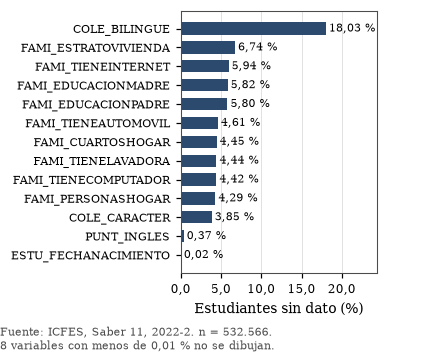

In [7]:
visibles = con_faltantes[con_faltantes["% faltante"] >= 0.01].iloc[::-1]
# Ancho pensado para que, con las etiquetas largas del eje vertical, la figura ocupe una columna sin reducirse.
figura, eje = plt.subplots(figsize=(2.3, 3.1))
barras = eje.barh(visibles.index, visibles["% faltante"], color=COLOR_PRINCIPAL, height=0.65)
eje.bar_label(barras, labels=[f"{en_espanol(v, 2)} %" for v in visibles["% faltante"]], padding=2, fontsize=7.5)
eje.set_xlabel("Estudiantes sin dato (%)")
eje.set_xlim(0, visibles["% faltante"].max() * 1.35)
eje.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: en_espanol(valor, 1)))
eje.grid(axis="y", visible=False)
eje.tick_params(axis="y", labelsize=7.5)
ocultas = len(con_faltantes) - len(visibles)
anotar_fuente(
    eje,
    f"Fuente: ICFES, Saber 11, 2022-2. n = {en_espanol(len(actual))}.\n"
    f"{ocultas} variables con menos de 0,01 % no se dibujan.",
)
cifra("variablesFaltantesVisibles", len(visibles))
cifra("variablesFaltantesOcultas", ocultas)
guardar_figura(figura, "faltantes")
plt.show()

**Lectura.** `COLE_BILINGUE` es la variable con más vacíos, casi uno de cada cinco estudiantes, muy por encima del resto. Le siguen las nueve variables del hogar, todas entre el 4 % y el 7 %, con el estrato a la cabeza, y `COLE_CARACTER`, cerca del 4 %. Los cinco puntajes distintos del de inglés están completos, y los demás atributos del colegio solo faltan en una fila. Eliminar por lista las filas incompletas descartaría alrededor de una cuarta parte de los estudiantes, así que la decisión de imputar depende del mecanismo de la falta (sección 4.4), que se analiza completo en la fase 2.

### 4.2. Valores atípicos

Se aplican las dos reglas que pide la guía a los seis puntajes: la de Tukey, que marca lo que queda a más de 1,5 rangos intercuartílicos de los cuartiles, y la de |z| > 3, que mide la distancia a la media en desviaciones estándar. Con medio millón de estudiantes, un atípico estadístico no es un error: se cuenta para saber cuánto pesan las colas, no para borrarlo.

In [8]:
def atipicos(valores: pd.Series) -> dict[str, float]:
    """Cuenta los atípicos de una variable por la regla de Tukey (1,5 IQR) y por |z| > 3."""
    valores = valores.dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera_iqr = int(((valores < inferior) | (valores > superior)).sum())
    z = (valores - valores.mean()) / valores.std(ddof=1)
    fuera_z = int((z.abs() > 3).sum())
    return {
        "n": len(valores),
        "Límite inferior": inferior,
        "Límite superior": superior,
        "Atípicos IQR": fuera_iqr,
        "% IQR": 100 * fuera_iqr / len(valores),
        "Atípicos |z|>3": fuera_z,
        "% z": 100 * fuera_z / len(valores),
    }


tabla_atipicos = pd.DataFrame({NOMBRE_PUNTAJE[c]: atipicos(actual[c]) for c in PUNTAJES}).T
print(tabla_atipicos.round(3).to_string())
for columna in PUNTAJES:
    fila = tabla_atipicos.loc[NOMBRE_PUNTAJE[columna]]
    sufijo = SUFIJO_PUNTAJE[columna]
    cifra(f"atipicosIqr{sufijo}", fila["Atípicos IQR"])
    cifra(f"pctAtipicosIqr{sufijo}", fila["% IQR"], 2)
    cifra(f"atipicosZ{sufijo}", fila["Atípicos |z|>3"])
    cifra(f"pctAtipicosZ{sufijo}", fila["% z"], 2)
    cifra(f"limiteInferior{sufijo}", fila["Límite inferior"], 1)
    cifra(f"limiteSuperior{sufijo}", fila["Límite superior"], 1)

                              n  Límite inferior  Límite superior  Atípicos IQR  % IQR  Atípicos |z|>3    % z
Global                 532566.0             93.0            405.0         696.0  0.131           698.0  0.131
Lectura crítica        532566.0             21.0             85.0         522.0  0.098           522.0  0.098
Matemáticas            532566.0             16.5             84.5        1133.0  0.213          1044.0  0.196
Ciencias naturales     532566.0             18.5             78.5         784.0  0.147           281.0  0.053
Sociales y ciudadanas  532566.0              9.5             85.5          58.0  0.011           131.0  0.025
Inglés                 530589.0             10.5             86.5        3601.0  0.679          3601.0  0.679


### 4.3. Incoherencias y codificaciones

Se revisan las cinco incoherencias que documenta la ficha del dataset o que aparecieron al explorar: puntajes globales en cero, fechas de nacimiento imposibles o ilegibles, la doble codificación de `FAMI_PERSONASHOGAR`, el nombre de Bogotá con y sin tilde y la frase rural del estrato. Una fecha es ilegible si no tiene la forma dd/mm/aaaa o trae un día o un mes fuera de rango, e imposible si da menos de 10 años o más de 100 al presentar el examen en 2022.

In [9]:
ceros = {NOMBRE_PUNTAJE[c]: int((actual[c] == 0).sum()) for c in PUNTAJES}
print("Estudiantes con puntaje 0:")
print(pd.Series(ceros).to_string())
cifra("cerosGlobal", ceros["Global"])
cifra("cerosIngles", ceros["Inglés"])

fechas = actual["ESTU_FECHANACIMIENTO"].dropna()
forma_valida = fechas.str.fullmatch(r"\d{2}/\d{2}/\d{4}")
dia = fechas.str[:2].where(forma_valida).astype(float)
mes = fechas.str[3:5].where(forma_valida).astype(float)
anio_nacimiento = fechas.str[-4:].where(forma_valida).astype(float)
ilegibles = int((~forma_valida | ~dia.between(1, 31) | ~mes.between(1, 12)).sum())
edad = ANIO_PERIODO[PERIODO_ACTUAL] - anio_nacimiento
imposibles = int(((edad < 10) | (edad > 100)).sum())
improbables = int(edad.between(10, 13).sum())
print(f"\nFechas de nacimiento registradas: {en_espanol(len(fechas))}")
print(f"Ilegibles: {ilegibles}")
print(f"Imposibles (menos de 10 o más de 100 años en 2022): {imposibles}")
print(f"  de ellas, en el año 1900, un valor de relleno típico: {int((anio_nacimiento == 1900).sum())}")
print(f"Improbables (de 10 a 13 años en 2022): {improbables}")
cifra("fechasIlegibles", ilegibles)
cifra("fechasImposibles", imposibles)
cifra("fechasImprobables", improbables)


def codificacion_personas(valores: list[str]) -> str:
    """Rangos ('3 a 4', '9 o más') o números en palabras ('Cuatro'), según los valores de un periodo."""
    con_digitos = sum(any(caracter.isdigit() for caracter in v) for v in valores)
    return "rangos" if con_digitos == len(valores) else "palabras" if con_digitos == 0 else "mezcla"


personas = (
    serie.group_by("PERIODO")
    .agg(pl.col("FAMI_PERSONASHOGAR").drop_nulls().unique().sort().alias("valores"))
    .sort("PERIODO")
    .collect()
    .to_pandas()
    .set_index("PERIODO")
)
personas["Codificación"] = personas["valores"].map(lambda v: codificacion_personas(list(v)))
personas["Valores distintos"] = personas["valores"].map(len)
print("\nCodificación de FAMI_PERSONASHOGAR por periodo:")
print(personas[["Codificación", "Valores distintos"]].rename(index=ETIQUETA_PERIODO).to_string())
comprobar("FAMI_PERSONASHOGAR usa palabras hasta 2016-2 y rangos desde 2017-2", list(personas["Codificación"]) == ["palabras"] * 3 + ["rangos"] * 3)

bogota = (
    serie.filter(pl.col("COLE_COD_DEPTO_UBICACION") == "11")
    .group_by("PERIODO")
    .agg(pl.col("COLE_DEPTO_UBICACION").unique().sort().str.join(", ").alias("Nombre"))
    .sort("PERIODO")
    .collect()
    .to_pandas()
    .set_index("PERIODO")
)
print("\nNombre del departamento con código DANE 11 por periodo:")
print(bogota.rename(index=ETIQUETA_PERIODO).to_string())
nombres_por_codigo = serie.group_by("PERIODO", "COLE_COD_DEPTO_UBICACION").agg(pl.col("COLE_DEPTO_UBICACION").n_unique()).collect()
comprobar("Dentro de cada periodo, cada código DANE de departamento tiene un solo nombre", nombres_por_codigo["COLE_DEPTO_UBICACION"].max() == 1)

frase_rural = serie.filter(pl.col("FAMI_ESTRATOVIVIENDA") == FRASE_RURAL).select(pl.len()).collect().item()
sin_estrato = dict(serie.filter(pl.col("FAMI_ESTRATOVIVIENDA") == "Sin Estrato").group_by("PERIODO").len().collect().iter_rows())
print(f"\nFilas con la frase rural en los seis periodos, después de unificarla: {frase_rural}")
print("Respuestas «Sin Estrato» por periodo:", {ETIQUETA_PERIODO[p]: en_espanol(n) for p, n in sorted(sin_estrato.items())})
cifra("sinEstratoDiecisiete", sin_estrato[20172])
cifra("sinEstratoVeintidos", sin_estrato[20224])

Estudiantes con puntaje 0:
Global                     4
Lectura crítica           79
Matemáticas               17
Ciencias naturales        25
Sociales y ciudadanas     13
Inglés                   876

Fechas de nacimiento registradas: 532.485
Ilegibles: 0
Imposibles (menos de 10 o más de 100 años en 2022): 109
  de ellas, en el año 1900, un valor de relleno típico: 9
Improbables (de 10 a 13 años en 2022): 143



Codificación de FAMI_PERSONASHOGAR por periodo:
        Codificación  Valores distintos
PERIODO                                
2014-2      palabras                 12
2015-2      palabras                 12
2016-2      palabras                 12
2017-2        rangos                  5
2019-2        rangos                  5
2022-2        rangos                  5
[ok] FAMI_PERSONASHOGAR usa palabras hasta 2016-2 y rangos desde 2017-2



Nombre del departamento con código DANE 11 por periodo:
         Nombre
PERIODO        
2014-2   BOGOTA
2015-2   BOGOTA
2016-2   BOGOTA
2017-2   BOGOTA
2019-2   BOGOTÁ
2022-2   BOGOTÁ
[ok] Dentro de cada periodo, cada código DANE de departamento tiene un solo nombre

Filas con la frase rural en los seis periodos, después de unificarla: 0
Respuestas «Sin Estrato» por periodo: {'2017-2': '14.114', '2019-2': '17.153', '2022-2': '19.770'}


'19.770'

**Lectura.** Los ceros del puntaje global son casos aislados; los de inglés son más frecuentes y, sin la hoja de respuestas, no se puede distinguir una prueba en blanco de un desempeño nulo. Ninguno se corrige en esta fase. Las fechas de nacimiento tienen todas la forma dd/mm/aaaa, pero algunas dan edades imposibles, entre ellas varias en el año 1900, que es un valor de relleno; la edad derivada de la fase 2 tendrá que tratarlas como faltantes. `FAMI_PERSONASHOGAR` cambió de números en palabras a rangos en 2017-2, así que la serie no se puede comparar sin armonizarla, y el nombre de Bogotá pierde o gana la tilde según el periodo: por eso el análisis geográfico agrupa por el código DANE, que es estable. «Sin Estrato» aparece por primera vez en 2017-2, el mismo año en que se rompe el orden del puntaje por estrato (sección 7).

### 4.4. Primera lectura del mecanismo de la falta

Si los faltantes de internet fueran completamente al azar (MCAR), los estudiantes sin respuesta tendrían un puntaje parecido al del conjunto. La comparación es solo un indicio; la prueba completa, con el indicador de faltante contra las variables observadas, va en la fase 2.

In [10]:
internet = actual["FAMI_TIENEINTERNET"].fillna("Sin respuesta")
mecanismo = actual.groupby(internet)["PUNT_GLOBAL"].agg(["size", "mean", "median"]).reindex(["Si", "No", "Sin respuesta"])
mecanismo.columns = ["Estudiantes", "Media", "Mediana"]
print(mecanismo.round(1).to_string())
for respuesta, sufijo in (("Si", "Si"), ("No", "No"), ("Sin respuesta", "Faltante")):
    cifra(f"mediaInternet{sufijo}", mecanismo.loc[respuesta, "Media"], 1)
comprobar(
    "La media del puntaje sin respuesta de internet está más cerca del «No» que del «Si»",
    abs(mecanismo.loc["Sin respuesta", "Media"] - mecanismo.loc["No", "Media"]) < abs(mecanismo.loc["Sin respuesta", "Media"] - mecanismo.loc["Si", "Media"]),
)

                    Estudiantes  Media  Mediana
FAMI_TIENEINTERNET                             
Si                       363657  260.2    259.0
No                       137266  228.4    223.0
Sin respuesta             31643  229.6    223.0
[ok] La media del puntaje sin respuesta de internet está más cerca del «No» que del «Si»


**Lectura.** Quien no responde si tiene internet obtiene un puntaje medio muy cercano al de quien responde que no, y lejano al de quien responde que sí. La falta no parece completamente al azar: se asocia con condiciones del hogar más precarias, y eliminar esas filas sesgaría el análisis hacia los hogares conectados.

## 5. Análisis univariado

### 5.1. Puntajes

Para cada puntaje se calculan las medidas de tendencia central (media, mediana y moda), de dispersión (varianza muestral, desviación estándar, rango y rango intercuartílico) y de forma. La asimetría es el coeficiente g1 sesgado y la curtosis se reporta en exceso sobre la normal (cero para una normal). Son las mismas definiciones que usa el script de R, para que la paridad de la sección 9 sea verificable.

In [11]:
def descriptivos(valores: pd.Series) -> dict[str, float]:
    """Medidas de tendencia central, dispersión y forma de una variable cuantitativa."""
    valores = valores.dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    return {
        "n": len(valores),
        "media": valores.mean(),
        "mediana": valores.median(),
        "moda": valores.mode().iloc[0],
        "varianza": valores.var(ddof=1),
        "desviacion": valores.std(ddof=1),
        "minimo": valores.min(),
        "maximo": valores.max(),
        "rango": valores.max() - valores.min(),
        "q1": q1,
        "q3": q3,
        "iqr": q3 - q1,
        "asimetria": stats.skew(valores, bias=True),
        "curtosis": stats.kurtosis(valores, fisher=True, bias=True),
    }


tabla_descriptivos = pd.DataFrame({columna: descriptivos(actual[columna]) for columna in PUNTAJES})
print(tabla_descriptivos.rename(columns=NOMBRE_PUNTAJE).round(3).to_string())

DECIMALES = {"n": 0, "media": 1, "mediana": 1, "moda": 0, "varianza": 1, "desviacion": 1, "minimo": 0, "maximo": 0, "rango": 0, "q1": 0, "q3": 0, "iqr": 0, "asimetria": 3, "curtosis": 3}
PREFIJO_MACRO = {"q1": "primerCuartil", "q3": "tercerCuartil"}
for columna in PUNTAJES:
    for medida, valor in tabla_descriptivos[columna].items():
        cifra(f"{PREFIJO_MACRO.get(medida, medida)}{SUFIJO_PUNTAJE[columna]}", valor, DECIMALES[medida])

                Global  Lectura crítica  Matemáticas  Ciencias naturales  Sociales y ciudadanas      Inglés
n           532566.000       532566.000   532566.000          532566.000             532566.000  530589.000
media          250.139           52.800       50.591              49.084                 47.703      49.864
mediana        247.000           53.000       51.000              48.000                 47.000      49.000
moda           237.000           53.000       52.000              43.000                 40.000      39.000
varianza      2687.524          116.003      149.609             107.853                142.181     171.699
desviacion      51.841           10.770       12.231              10.385                 11.924      13.103
minimo           0.000            0.000        0.000               0.000                  0.000       0.000
maximo         477.000          100.000      100.000             100.000                100.000     100.000
rango          477.000      

La fecha de nacimiento es la única variable cuantitativa continua del recorte. Se resume a través de la edad al presentar el examen, aproximada como 2022 menos el año de nacimiento, sin las fechas imposibles de la sección 4.3. La fase 2 la convierte en la variable derivada «edad».

In [12]:
edad_posible = edad[edad.between(10, 100)]
descriptivos_edad = descriptivos(edad_posible)
print(pd.Series(descriptivos_edad).round(3).to_string())
comprobar("La edad se resume sobre las fechas posibles", descriptivos_edad["n"] == len(fechas) - imposibles)
for medida, valor in descriptivos_edad.items():
    cifra(f"edad{PREFIJO_MACRO.get(medida, medida).capitalize()}", valor, 3 if medida in ("asimetria", "curtosis") else 1 if medida in ("media", "desviacion", "varianza") else 0)

n             532376.000
media             17.593
mediana           17.000
moda              17.000
varianza           7.832
desviacion         2.799
minimo            10.000
maximo            87.000
rango             77.000
q1                17.000
q3                18.000
iqr                1.000
asimetria          8.085
curtosis          91.285
[ok] La edad se resume sobre las fechas posibles


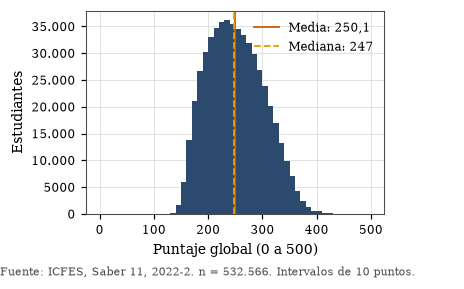

In [13]:
puntaje = actual["PUNT_GLOBAL"]
media_global, mediana_global = puntaje.mean(), puntaje.median()
figura, eje = plt.subplots(figsize=(3.5, 2.4))
eje.hist(puntaje, bins=np.arange(0, 510, 10), color=COLOR_PRINCIPAL)
eje.axvline(media_global, color=PALETA_CATEGORICA[1], linewidth=1.2, label=f"Media: {en_espanol(media_global, 1)}")
eje.axvline(mediana_global, color=PALETA_CATEGORICA[5], linewidth=1.2, linestyle="--", label=f"Mediana: {en_espanol(mediana_global, 0)}")
eje.set_xlabel("Puntaje global (0 a 500)")
eje.set_ylabel("Estudiantes")
eje.yaxis.set_major_formatter(FORMATO_MILES)
eje.legend(loc="upper right")
anotar_fuente(eje, f"Fuente: ICFES, Saber 11, 2022-2. n = {en_espanol(len(puntaje))}. Intervalos de 10 puntos.")
guardar_figura(figura, "histograma-global")
plt.show()

**Lectura.** Un histograma se lee por su forma: cuántos picos tiene, dónde está el centro, qué tan ancho es y hacia qué lado se alarga. El del puntaje global tiene un solo pico, la media y la mediana casi coinciden y la cola derecha es algo más larga que la izquierda, lo que concuerda con una asimetría positiva pequeña; la curtosis en exceso es negativa, así que las colas son algo más livianas que las de una normal. La mitad central de los estudiantes ocupa un tramo estrecho de la escala de 0 a 500, y por encima de 400 puntos quedan muy pocos. Para la regresión de la fase 2 eso significa que el puntaje no necesita transformarse para tener una forma razonable.

### 5.2. Variables cualitativas

Las tablas de frecuencias muestran el conteo absoluto y el porcentaje sobre quienes responden; el faltante se informa aparte. Las variables ordinales siguen su orden natural y las nominales, el de la frecuencia. Los departamentos se resumen en el agregado de la sección 10.

In [14]:
def frecuencias(columna: str) -> pd.DataFrame:
    """Frecuencia absoluta y relativa de una variable cualitativa, con el faltante en una fila aparte."""
    conteos = actual[columna].value_counts()
    if columna in ORDENES:
        conteos = conteos.reindex([v for v in ORDENES[columna] if v in conteos.index])
    tabla = pd.DataFrame({"Estudiantes": conteos, "% de quienes responden": 100 * conteos / conteos.sum()})
    tabla.loc["(sin respuesta)"] = [actual[columna].isna().sum(), np.nan]
    return tabla


CUALITATIVAS = [c for c, v in VARIABLES.items() if v.tipo.startswith("cualitativa") and c not in ("PERIODO", "COLE_COD_DEPTO_UBICACION", "COLE_DEPTO_UBICACION")]
tablas_frecuencia = {columna: frecuencias(columna) for columna in CUALITATIVAS}
for columna, tabla in tablas_frecuencia.items():
    print(f"\n{columna}")
    print(tabla.round(2).to_string())

for estrato in ORDEN_ESTRATO:
    cifra(f"pctEstrato{SUFIJO_ESTRATO[estrato]}", tablas_frecuencia["FAMI_ESTRATOVIVIENDA"].loc[estrato, "% de quienes responden"], 1)
    cifra(f"estudiantesEstrato{SUFIJO_ESTRATO[estrato]}", tablas_frecuencia["FAMI_ESTRATOVIVIENDA"].loc[estrato, "Estudiantes"])
estratos_bajos = tablas_frecuencia["FAMI_ESTRATOVIVIENDA"].loc[ORDEN_ESTRATO[:3], "% de quienes responden"].sum()
cifra("pctEstratosUnoATres", estratos_bajos, 1)
cifra("pctInternetSi", tablas_frecuencia["FAMI_TIENEINTERNET"].loc["Si", "% de quienes responden"], 1)
cifra("pctComputadorSi", tablas_frecuencia["FAMI_TIENECOMPUTADOR"].loc["Si", "% de quienes responden"], 1)
cifra("pctRural", tablas_frecuencia["COLE_AREA_UBICACION"].loc["RURAL", "% de quienes responden"], 1)
cifra("pctMadreSecundariaCompleta", tablas_frecuencia["FAMI_EDUCACIONMADRE"].loc["Secundaria (Bachillerato) completa", "% de quienes responden"], 1)
cifra("pctMujeres", tablas_frecuencia["ESTU_GENERO"].loc["F", "% de quienes responden"], 1)
cifra("pctCalendarioA", tablas_frecuencia["COLE_CALENDARIO"].loc["A", "% de quienes responden"], 1)


FAMI_ESTRATOVIVIENDA
                      Estudiantes  % de quienes responden
FAMI_ESTRATOVIVIENDA                                     
Estrato 1                  146261                   29.45
Estrato 2                  180019                   36.25
Estrato 3                  110215                   22.19
Estrato 4                   28080                    5.65
Estrato 5                    8445                    1.70
Estrato 6                    3879                    0.78
Sin Estrato                 19770                    3.98
(sin respuesta)             35897                     NaN

FAMI_EDUCACIONMADRE
                                      Estudiantes  % de quienes responden
FAMI_EDUCACIONMADRE                                                      
Ninguno                                     10258                    2.05
Primaria incompleta                         62853                   12.53
Primaria completa                           42105                    8.39
Secunda

'99,6'

In [15]:
naturaleza = tablas_frecuencia["COLE_NATURALEZA"]
pct_oficial = naturaleza.loc["OFICIAL", "% de quienes responden"]
razon = naturaleza.loc["OFICIAL", "Estudiantes"] / naturaleza.loc["NO OFICIAL", "Estudiantes"]
print(f"Oficial: {en_espanol(pct_oficial, 1)} %; no oficial: {en_espanol(100 - pct_oficial, 1)} %")
print(f"Estudiantes de colegio oficial por cada uno de colegio no oficial: {en_espanol(razon, 2)}")
cifra("pctOficial", pct_oficial, 1)
cifra("pctNoOficial", 100 - pct_oficial, 1)
cifra("razonOficial", razon, 1)

Oficial: 77,4 %; no oficial: 22,6 %
Estudiantes de colegio oficial por cada uno de colegio no oficial: 3,42


'3,4'

**Lectura.** Tres de cada cuatro estudiantes estudian en un colegio oficial. Para la clasificación de la fase 3 es un desbalance moderado: un clasificador que respondiera siempre «oficial» acertaría en esa misma proporción sin aprender nada, así que la exactitud no sirve como métrica y se usarán F1 y AUC-ROC. La mayoría de los estudiantes declara los estratos 1 a 3, y los estratos 5 y 6 juntos son una fracción pequeña, por lo que cualquier análisis por estrato tiene que mirar el tamaño de cada grupo antes de comparar medianas.

## 6. Análisis bivariado y multivariado

### 6.1. Correlación entre los puntajes

Se calculan las matrices de Pearson (relación lineal) y de Spearman (relación monótona, sobre rangos) entre los seis puntajes, con los estudiantes que tienen los seis completos.

Estudiantes con los seis puntajes: 530.589

Pearson:
           Global  Lectura  Matemát.  Naturales  Sociales  Inglés
Global      1.000    0.911     0.908      0.921     0.917   0.802
Lectura     0.911    1.000     0.765      0.777     0.808   0.706
Matemát.    0.908    0.765     1.000      0.811     0.750   0.677
Naturales   0.921    0.777     0.811      1.000     0.803   0.716
Sociales    0.917    0.808     0.750      0.803     1.000   0.698
Inglés      0.802    0.706     0.677      0.716     0.698   1.000

Spearman:
           Global  Lectura  Matemát.  Naturales  Sociales  Inglés
Global      1.000    0.914     0.909      0.916     0.917   0.792
Lectura     0.914    1.000     0.770      0.778     0.815   0.709
Matemát.    0.909    0.770     1.000      0.812     0.754   0.679
Naturales   0.916    0.778     0.812      1.000     0.798   0.701
Sociales    0.917    0.815     0.754      0.798     1.000   0.689
Inglés      0.792    0.709     0.679      0.701     0.689   1.000


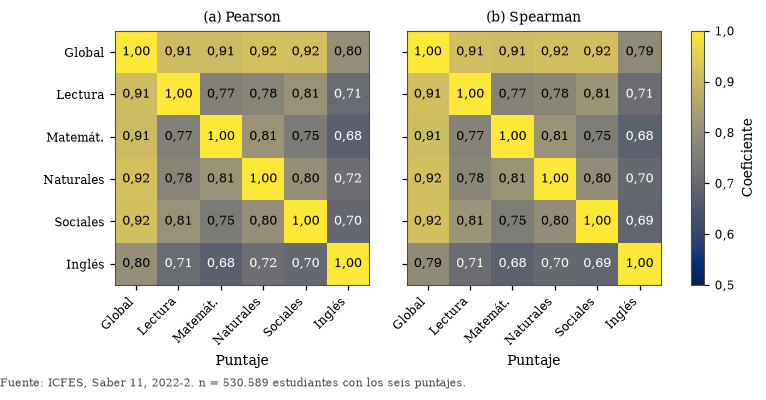

In [16]:
completos = actual.dropna(subset=PUNTAJES)
pearson = completos[PUNTAJES].corr(method="pearson")
spearman = completos[PUNTAJES].corr(method="spearman")
etiquetas_cortas = ["Global", "Lectura", "Matemát.", "Naturales", "Sociales", "Inglés"]
print(f"Estudiantes con los seis puntajes: {en_espanol(len(completos))}")
print("\nPearson:")
print(pearson.set_axis(etiquetas_cortas, axis=0).set_axis(etiquetas_cortas, axis=1).round(3).to_string())
print("\nSpearman:")
print(spearman.set_axis(etiquetas_cortas, axis=0).set_axis(etiquetas_cortas, axis=1).round(3).to_string())

cifra("estudiantesSeisPuntajes", len(completos))
for columna in PUNTAJES[1:]:
    cifra(f"pearsonGlobal{SUFIJO_PUNTAJE[columna]}", pearson.loc["PUNT_GLOBAL", columna], 2)
    cifra(f"spearmanGlobal{SUFIJO_PUNTAJE[columna]}", spearman.loc["PUNT_GLOBAL", columna], 2)
areas_pearson = pearson.loc[AREAS, AREAS].where(~np.eye(len(AREAS), dtype=bool))
ingles_pearson = pearson.loc["PUNT_INGLES", AREAS]
cifra("pearsonAreasMinima", areas_pearson.min().min(), 2)
cifra("pearsonAreasMaxima", areas_pearson.max().max(), 2)
cifra("pearsonInglesMinima", ingles_pearson.min(), 2)
cifra("pearsonInglesMaxima", ingles_pearson.max(), 2)
cifra("pearsonMatematicasLectura", pearson.loc["PUNT_MATEMATICAS", "PUNT_LECTURA_CRITICA"], 2)
cifra("diferenciaMaximaPearsonSpearman", (pearson - spearman).abs().max().max(), 3)


MINIMO_ESCALA_CORRELACION = 0.5
UMBRAL_TEXTO_OSCURO = 0.75


def dibujar_correlacion(eje: plt.Axes, matriz: pd.DataFrame, titulo: str):
    imagen = eje.imshow(matriz.to_numpy(), cmap="cividis", vmin=MINIMO_ESCALA_CORRELACION, vmax=1)
    eje.set_xticks(range(len(etiquetas_cortas)), etiquetas_cortas, rotation=45, ha="right")
    eje.set_yticks(range(len(etiquetas_cortas)), etiquetas_cortas)
    eje.grid(False)
    for i in range(len(matriz)):
        for j in range(len(matriz)):
            valor = matriz.iat[i, j]
            eje.text(j, i, en_espanol(valor, 2), ha="center", va="center", fontsize=8.5, color="black" if valor >= UMBRAL_TEXTO_OSCURO else "white")
    eje.set_title(titulo)
    return imagen


figura, (eje_p, eje_s, eje_barra) = plt.subplots(1, 3, figsize=(7.0, 3.0), gridspec_kw={"width_ratios": [1, 1, 0.05], "wspace": 0.12})
dibujar_correlacion(eje_p, pearson, "(a) Pearson")
imagen = dibujar_correlacion(eje_s, spearman, "(b) Spearman")
eje_s.tick_params(labelleft=False)
barra = figura.colorbar(imagen, cax=eje_barra)
barra.set_label("Coeficiente")
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: en_espanol(valor, 1)))
for eje in (eje_p, eje_s):
    eje.set_xlabel("Puntaje")
anotar_fuente(eje_p, f"Fuente: ICFES, Saber 11, 2022-2. n = {en_espanol(len(completos))} estudiantes con los seis puntajes.")
guardar_figura(figura, "correlaciones")
plt.show()

**Lectura.** Todas las correlaciones son positivas y altas, y las dos matrices casi coinciden, de modo que la relación entre áreas es esencialmente lineal. La fila del puntaje global merece una advertencia, la misma que hizo el docente en clase sobre las variables casi idénticas: el global se correlaciona por encima de 0,9 con las cuatro áreas porque se calcula con ellas. La sección siguiente lo demuestra.

### 6.2. La fórmula del puntaje global

El puntaje global se obtiene de las cinco pruebas: cada área pesa tres veces y el inglés una, sobre 13, llevado a la escala de 0 a 500 y redondeado. Se comprueba la fórmula con el redondeo al par más cercano y con el redondeo hacia arriba en las mitades.

In [17]:
suma_ponderada = 3 * completos[AREAS].sum(axis=1) + completos["PUNT_INGLES"]
calculado = 5 * suma_ponderada / 13
coincide_par = (np.round(calculado) == completos["PUNT_GLOBAL"]).mean()
coincide_arriba = (np.floor(calculado + 0.5) == completos["PUNT_GLOBAL"]).mean()
print("PUNT_GLOBAL = redondeo(5 × (3 × (lectura + matemáticas + naturales + sociales) + inglés) / 13)")
print(f"Coincide en el {en_espanol(100 * coincide_par, 4)} % de {en_espanol(len(completos))} filas (redondeo al par)")
print(f"Coincide en el {en_espanol(100 * coincide_arriba, 4)} % de {en_espanol(len(completos))} filas (redondeo hacia arriba)")
comprobar("La fórmula del puntaje global es exacta en todas las filas completas", coincide_par == 1 and coincide_arriba == 1)
cifra("pctFormulaExacta", 100 * coincide_par, 0)

PUNT_GLOBAL = redondeo(5 × (3 × (lectura + matemáticas + naturales + sociales) + inglés) / 13)
Coincide en el 100,0000 % de 530.589 filas (redondeo al par)
Coincide en el 100,0000 % de 530.589 filas (redondeo hacia arriba)
[ok] La fórmula del puntaje global es exacta en todas las filas completas


'100'

**Lectura.** La fórmula se cumple en todas las filas con los seis puntajes. El puntaje global no es una variable independiente de las áreas: es una combinación lineal suya. De ahí sale la decisión que el proyecto declara desde esta fase: la regresión de S1 no puede usar los puntajes por área ni el de inglés como predictores, porque el modelo aprendería la fórmula y no la relación con el hogar y el colegio. Por la misma razón, la segmentación de S3 trabaja con las cinco pruebas y deja fuera el global.

### 6.3. Dispersión de dos áreas: matemáticas frente a lectura crítica

Con medio millón de estudiantes y puntajes enteros, una nube de puntos se satura. El diagrama de celdas hexagonales cuenta los estudiantes de cada celda y los colorea en escala logarítmica. Las celdas con menos de 10 estudiantes no se dibujan, con la misma regla de los agregados de la sección 10.

Pares de puntajes distintos: 3207; estudiantes por par, en promedio: 166,1


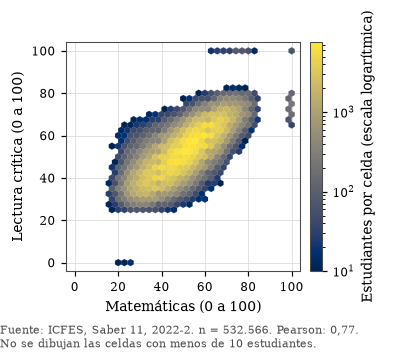

Estudiantes en la celda más poblada: 7559


'7559'

In [18]:
matematicas, lectura = actual["PUNT_MATEMATICAS"], actual["PUNT_LECTURA_CRITICA"]
pares_distintos = actual[["PUNT_MATEMATICAS", "PUNT_LECTURA_CRITICA"]].drop_duplicates().shape[0]
print(f"Pares de puntajes distintos: {en_espanol(pares_distintos)}; estudiantes por par, en promedio: {en_espanol(len(actual) / pares_distintos, 1)}")
cifra("paresDistintos", pares_distintos)
cifra("estudiantesPorPar", len(actual) / pares_distintos, 1)

figura, (eje_hex, eje_barra) = plt.subplots(1, 2, figsize=(3.0, 2.7), gridspec_kw={"width_ratios": [1, 0.05], "wspace": 0.08})
hexagonos = eje_hex.hexbin(matematicas, lectura, gridsize=35, extent=(0, 100, 0, 100), bins="log", cmap="cividis", mincnt=MINIMO_POR_CELDA, linewidths=0.1)
celda_maxima = hexagonos.get_array().max()
figura.colorbar(hexagonos, cax=eje_barra).set_label("Estudiantes por celda (escala logarítmica)")
eje_hex.set_xlim(-4, 104)
eje_hex.set_ylim(-4, 104)
eje_hex.set_xlabel("Matemáticas (0 a 100)")
eje_hex.set_ylabel("Lectura crítica (0 a 100)")
anotar_fuente(
    eje_hex,
    f"Fuente: ICFES, Saber 11, 2022-2. n = {en_espanol(len(actual))}. Pearson: {en_espanol(pearson.loc['PUNT_MATEMATICAS', 'PUNT_LECTURA_CRITICA'], 2)}.\n"
    f"No se dibujan las celdas con menos de {MINIMO_POR_CELDA} estudiantes.",
)
guardar_figura(figura, "hexbin-matematicas-lectura")
plt.show()
print(f"Estudiantes en la celda más poblada: {en_espanol(celda_maxima)}")
cifra("celdaMaxima", celda_maxima)

**Lectura.** La nube forma una banda diagonal concentrada en el centro de la escala, coherente con la correlación de Pearson entre las dos áreas. La escala logarítmica deja ver a la vez el núcleo, donde una sola celda reúne miles de estudiantes, y las colas, donde quedan unas decenas; un diagrama de dispersión de un punto por estudiante habría pintado todo con el mismo peso. La fila en 100 de lectura crítica y la columna en 100 de matemáticas quedan separadas del resto de la nube por un salto de varios puntos, un rasgo de la escala que conviene tener presente al leer los atípicos.

### 6.4. Puntaje global por estrato y naturaleza del colegio

El diagrama de caja muestra la mediana, los cuartiles y los bigotes hasta 1,5 rangos intercuartílicos, sin dibujar los atípicos. El panel de la izquierda agrega a todos los estudiantes y el de la derecha separa los colegios oficiales de los no oficiales.

In [19]:
con_estrato = actual.dropna(subset=["FAMI_ESTRATOVIVIENDA"])
con_ambos = con_estrato.dropna(subset=["COLE_NATURALEZA"])
mediana_estrato = con_estrato.groupby("FAMI_ESTRATOVIVIENDA")["PUNT_GLOBAL"].median().reindex(ORDEN_ESTRATO)
cruce = con_ambos.groupby(["FAMI_ESTRATOVIVIENDA", "COLE_NATURALEZA"])["PUNT_GLOBAL"]
mediana_cruce = cruce.median().unstack().reindex(index=ORDEN_ESTRATO, columns=NATURALEZAS)
estudiantes_cruce = cruce.size().unstack().reindex(index=ORDEN_ESTRATO, columns=NATURALEZAS)
cuadro_estrato = pd.DataFrame(
    {
        "Mediana": mediana_estrato,
        "Mediana oficial": mediana_cruce["OFICIAL"],
        "Mediana no oficial": mediana_cruce["NO OFICIAL"],
        "En oficial": estudiantes_cruce["OFICIAL"],
        "En no oficial": estudiantes_cruce["NO OFICIAL"],
        "% en oficial": 100 * estudiantes_cruce["OFICIAL"] / estudiantes_cruce.sum(axis=1),
    }
)
print(cuadro_estrato.round(1).to_string())
comprobar("Cada celda del cruce estrato por naturaleza tiene 10 o más estudiantes", estudiantes_cruce.min().min() >= MINIMO_POR_CELDA)
comprobar("En el agregado, la mediana del estrato 6 queda por debajo de la del estrato 4", mediana_estrato["Estrato 6"] < mediana_estrato["Estrato 4"])
comprobar("En los colegios no oficiales, la mediana del estrato 6 supera a la del estrato 1", mediana_cruce.loc["Estrato 6", "NO OFICIAL"] > mediana_cruce.loc["Estrato 1", "NO OFICIAL"])
for estrato in ORDEN_ESTRATO:
    sufijo = SUFIJO_ESTRATO[estrato]
    cifra(f"medianaEstrato{sufijo}", mediana_estrato[estrato], 0)
    cifra(f"medianaOficialEstrato{sufijo}", mediana_cruce.loc[estrato, "OFICIAL"], 0)
    cifra(f"medianaNoOficialEstrato{sufijo}", mediana_cruce.loc[estrato, "NO OFICIAL"], 0)
    cifra(f"pctOficialEstrato{sufijo}", cuadro_estrato.loc[estrato, "% en oficial"], 1)

                      Mediana  Mediana oficial  Mediana no oficial  En oficial  En no oficial  % en oficial
FAMI_ESTRATOVIVIENDA                                                                                       
Estrato 1               238.0            238.0               240.0      130863          15398          89.5
Estrato 2               252.0            249.0               267.0      144954          35065          80.5
Estrato 3               263.0            251.0               287.0       70704          39511          64.2
Estrato 4               269.0            224.0               304.0       13157          14923          46.9
Estrato 5               258.0            206.0               310.0        3864           4581          45.8
Estrato 6               230.0            192.0               307.0        2152           1727          55.5
Sin Estrato             203.0            202.0               216.0       17790           1980          90.0
[ok] Cada celda del cruce es

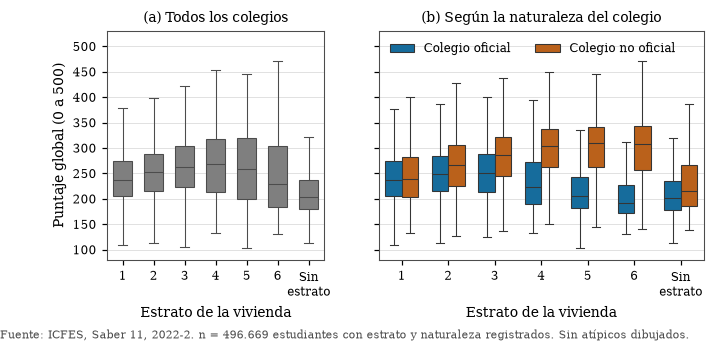

In [20]:
figura, (eje_agregado, eje_separado) = plt.subplots(1, 2, figsize=(7.0, 2.7), sharey=True, gridspec_kw={"width_ratios": [1, 1.5]})
sns.boxplot(data=con_estrato, x="FAMI_ESTRATOVIVIENDA", y="PUNT_GLOBAL", order=ORDEN_ESTRATO, color=COLOR_APOYO, showfliers=False, width=0.6, linewidth=0.7, ax=eje_agregado)
sns.boxplot(
    data=con_ambos,
    x="FAMI_ESTRATOVIVIENDA",
    y="PUNT_GLOBAL",
    order=ORDEN_ESTRATO,
    hue="COLE_NATURALEZA",
    hue_order=NATURALEZAS,
    palette=[COLOR_OFICIAL, COLOR_NO_OFICIAL],
    showfliers=False,
    width=0.7,
    linewidth=0.7,
    ax=eje_separado,
)
for eje, titulo in ((eje_agregado, "(a) Todos los colegios"), (eje_separado, "(b) Según la naturaleza del colegio")):
    eje.set_xticks(range(len(ORDEN_ESTRATO)), [ETIQUETA_ESTRATO[e] for e in ORDEN_ESTRATO])
    eje.set_xlabel("Estrato de la vivienda")
    eje.set_title(titulo)
eje_agregado.set_ylabel("Puntaje global (0 a 500)")
eje_agregado.set_ylim(80, 530)
manijas, _ = eje_separado.get_legend_handles_labels()
eje_separado.legend(manijas, ["Colegio oficial", "Colegio no oficial"], loc="upper left", ncols=2)
anotar_fuente(
    eje_agregado,
    f"Fuente: ICFES, Saber 11, 2022-2. n = {en_espanol(len(con_ambos))} estudiantes con estrato y naturaleza registrados. Sin atípicos dibujados.",
)
guardar_figura(figura, "caja-estrato-naturaleza")
plt.show()

**Lectura.** En el panel (a) la mediana sube del estrato 1 al 4 y después baja, hasta quedar el estrato 6 por debajo del 1; leída sola, la figura atribuiría al estrato en general una caída que el panel (b) ubica en un solo grupo. En los colegios no oficiales la mediana sube con el estrato hasta el 5 y se sostiene en el 6. En los oficiales, en cambio, cae desde el estrato 4, y en el estrato 6 la mayoría de los estudiantes está en colegios oficiales, de modo que el agregado hereda la caída de ese grupo y, por su peso, la arrastra al conjunto. La sección 7 muestra que esa caída aparece en 2017-2. Por eso la pregunta principal pone el hogar y el colegio juntos.

### 6.5. Puntaje global según las variables de la pregunta principal

La pregunta principal nombra siete variables: estrato, educación de los padres (aquí, la de la madre), internet y computador del hogar, y naturaleza, zona y jornada del colegio. Para cada categoría se reporta el número de estudiantes, su porcentaje sobre quienes responden y la mediana del puntaje global; la fila «sin respuesta» muestra el puntaje de quienes no contestan, que es la primera lectura del mecanismo de la falta. Todas las celdas tienen 10 o más estudiantes: en las tres variables del colegio el faltante es de un solo estudiante, así que esa fila no se muestra. Las pruebas formales de estas diferencias corresponden a la fase 3.

In [21]:
VARIABLES_PREGUNTA = ["FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR", "COLE_NATURALEZA", "COLE_AREA_UBICACION", "COLE_JORNADA"]
SIN_RESPUESTA = "(sin respuesta)"
NUMEROS = dict(enumerate(["Cero", "Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis", "Siete", "Ocho", "Nueve"]))


def sufijo_categoria(categoria: str) -> str:
    """Sufijo de macro (solo letras) para una categoría: sin tildes, dígitos en palabras."""
    sin_tildes = "".join(c for c in unicodedata.normalize("NFKD", categoria) if not unicodedata.combining(c))
    partes = re.findall(r"[A-Za-z]+|\d", sin_tildes)
    return "".join(NUMEROS[int(parte)] if parte.isdigit() else parte.capitalize() for parte in partes)


def puntaje_por_categoria(columna: str) -> pd.DataFrame:
    """Frecuencia y mediana del puntaje global por categoría, con el faltante como categoría aparte.

    Si el faltante tiene menos de 10 estudiantes, su fila se omite: su mediana revelaría puntajes
    individuales. Su conteo queda en la tabla de faltantes de la sección 4.1.
    """
    tabla = tablas_frecuencia[columna].copy()
    if tabla.loc[SIN_RESPUESTA, "Estudiantes"] < MINIMO_POR_CELDA:
        tabla = tabla.drop(SIN_RESPUESTA)
    grupos = actual["PUNT_GLOBAL"].groupby(actual[columna].fillna(SIN_RESPUESTA))
    tabla["Mediana del puntaje global"] = grupos.median().reindex(tabla.index)
    return tabla


cruces_pregunta = {columna: puntaje_por_categoria(columna) for columna in VARIABLES_PREGUNTA}
for columna, tabla in cruces_pregunta.items():
    print(f"\n{columna}")
    print(tabla.round(1).to_string())
    comprobar(f"{columna}: cada categoría tiene 10 o más estudiantes", tabla["Estudiantes"].min() >= MINIMO_POR_CELDA)
    for categoria, fila in tabla.iterrows():
        sufijo = nombre_macro(columna) + ("Sin" if categoria == SIN_RESPUESTA else sufijo_categoria(categoria))
        cifra(f"frec{sufijo}", fila["Estudiantes"])
        cifra(f"mediana{sufijo}", fila["Mediana del puntaje global"], 0)
        if categoria != SIN_RESPUESTA:
            cifra(f"pct{sufijo}", fila["% de quienes responden"], 1)
comprobar("Los sufijos de las categorías no se repiten dentro de cada variable", all(len({sufijo_categoria(c) for c in t.index}) == len(t) for t in cruces_pregunta.values()))

madre = cruces_pregunta["FAMI_EDUCACIONMADRE"]["Mediana del puntaje global"]
brecha_madre = madre["Postgrado"] - madre["Ninguno"]
jornada = cruces_pregunta["COLE_JORNADA"]["Mediana del puntaje global"].drop(SIN_RESPUESTA, errors="ignore")
print(f"\nDiferencia de medianas entre madre con posgrado y sin estudios: {brecha_madre:.0f} puntos")
print(f"Jornada con la mediana más alta: {jornada.idxmax()}; más baja: {jornada.idxmin()}")
cifra("brechaMadre", brecha_madre, 0)


FAMI_ESTRATOVIVIENDA
                      Estudiantes  % de quienes responden  Mediana del puntaje global
FAMI_ESTRATOVIVIENDA                                                                 
Estrato 1                  146261                    29.4                       238.0
Estrato 2                  180019                    36.2                       252.0
Estrato 3                  110215                    22.2                       263.0
Estrato 4                   28080                     5.7                       269.0
Estrato 5                    8445                     1.7                       258.0
Estrato 6                    3879                     0.8                       230.0
Sin Estrato                 19770                     4.0                       203.0
(sin respuesta)             35897                     NaN                       224.0
[ok] FAMI_ESTRATOVIVIENDA: cada categoría tiene 10 o más estudiantes

FAMI_EDUCACIONMADRE
                            

'113'

**Lectura.** La educación de la madre ordena el puntaje casi como una escalera: la mediana sube con cada nivel, de «Ninguno» a «Postgrado», con una distancia de más de cien puntos entre los extremos, mientras que tener computador o internet en el hogar se asocia con una mediana más alta en ambos casos. En el colegio, las sedes rurales y las jornadas nocturna y sabatina quedan por debajo, y la jornada completa por encima. Las filas «sin respuesta» se parecen a las categorías de menor puntaje en todas las variables del hogar, lo que refuerza la lectura de la sección 4.4. Ninguna de estas diferencias se interpreta todavía como efecto: las variables están asociadas entre sí (sección 6.6) y la fase 3 las prueba con su tamaño de efecto.

### 6.6. Pruebas de independencia (H4)

La hipótesis H4 del proyecto plantea que el estrato y la naturaleza del colegio no son independientes, y que el internet del hogar y la zona del colegio tampoco. Se aplica la prueba χ² de Pearson sin corrección de continuidad y se mide el tamaño del efecto con la V de Cramér, porque con más de medio millón de estudiantes cualquier diferencia mínima da un valor p cercano a cero. Las tablas usan solo los estudiantes con las dos variables registradas, y «Sin Estrato» cuenta como categoría.

In [22]:
def chi_cuadrado(tabla: pd.DataFrame) -> dict[str, float]:
    """Prueba χ² de independencia sin corrección de Yates y V de Cramér sin corrección de sesgo."""
    resultado = stats.chi2_contingency(tabla.to_numpy(), correction=False)
    n = int(tabla.to_numpy().sum())
    return {
        "n": n,
        "estadistico": float(resultado.statistic),
        "gl": int(resultado.dof),
        "p": float(resultado.pvalue),
        "v_cramer": float(np.sqrt(resultado.statistic / (n * (min(tabla.shape) - 1)))),
        "esperada_minima": float(resultado.expected_freq.min()),
    }


tabla_estrato = pd.crosstab(actual["FAMI_ESTRATOVIVIENDA"], actual["COLE_NATURALEZA"]).reindex(index=ORDEN_ESTRATO, columns=NATURALEZAS)
tabla_internet = pd.crosstab(actual["FAMI_TIENEINTERNET"], actual["COLE_AREA_UBICACION"]).reindex(index=["Si", "No"], columns=["URBANO", "RURAL"])
PRUEBAS_H4 = {"estrato_naturaleza": tabla_estrato, "internet_zona": tabla_internet}
resultados_h4 = {}
for nombre, tabla in PRUEBAS_H4.items():
    print(f"\n{nombre}:")
    print(tabla.to_string())
    comprobar(f"La tabla {nombre} no tiene celdas de menos de 10 estudiantes", tabla.to_numpy().min() >= MINIMO_POR_CELDA)
    resultados_h4[nombre] = chi_cuadrado(tabla)
    comprobar(f"La tabla {nombre} tiene frecuencias esperadas de 5 o más", resultados_h4[nombre]["esperada_minima"] >= 5)
print()
print(pd.DataFrame(resultados_h4).T.to_string())

for nombre, sufijo in (("estrato_naturaleza", "EstratoNaturaleza"), ("internet_zona", "InternetZona")):
    resultado = resultados_h4[nombre]
    cifra(f"chiDos{sufijo}", resultado["estadistico"], 0)
    cifra(f"gl{sufijo}", resultado["gl"])
    cifra(f"vCramer{sufijo}", resultado["v_cramer"], 3)
    cifra(f"n{sufijo}", resultado["n"])
    comprobar(f"El valor p de {nombre} es menor que 0,001", resultado["p"] < 0.001)
tasa_internet = tabla_internet.div(tabla_internet.sum(axis=0), axis=1).loc["Si"] * 100
print(f"\nCon internet: urbano {en_espanol(tasa_internet['URBANO'], 1)} %, rural {en_espanol(tasa_internet['RURAL'], 1)} %")
cifra("pctInternetUrbano", tasa_internet["URBANO"], 1)
cifra("pctInternetRural", tasa_internet["RURAL"], 1)


estrato_naturaleza:
COLE_NATURALEZA       OFICIAL  NO OFICIAL
FAMI_ESTRATOVIVIENDA                     
Estrato 1              130863       15398
Estrato 2              144954       35065
Estrato 3               70704       39511
Estrato 4               13157       14923
Estrato 5                3864        4581
Estrato 6                2152        1727
Sin Estrato             17790        1980
[ok] La tabla estrato_naturaleza no tiene celdas de menos de 10 estudiantes
[ok] La tabla estrato_naturaleza tiene frecuencias esperadas de 5 o más

internet_zona:
COLE_AREA_UBICACION  URBANO  RURAL
FAMI_TIENEINTERNET                
Si                   324576  39081
No                    91333  45933
[ok] La tabla internet_zona no tiene celdas de menos de 10 estudiantes
[ok] La tabla internet_zona tiene frecuencias esperadas de 5 o más

                           n   estadistico   gl    p  v_cramer  esperada_minima
estrato_naturaleza  496669.0  46630.680489  6.0  0.0  0.306410       883.97829

'46,0'

**Lectura.** Las dos pruebas rechazan la independencia con un valor p prácticamente nulo, como era de esperar con este tamaño de muestra; lo que se interpreta es la V de Cramér. La asociación entre estrato y naturaleza es la más fuerte de las dos: la proporción de estudiantes en colegios no oficiales sube desde el estrato 1 hasta pasar de la mitad en los estratos 4 y 5, y vuelve a bajar en el 6, donde los oficiales son mayoría. La de internet y zona es más débil, pero la brecha de conectividad entre sedes urbanas y rurales es clara. Las dos asociaciones anticipan colinealidad entre predictores del hogar y del colegio en la fase 2.

## 7. La serie de 2014-2 a 2022-2

La serie se agrega en polars y pasa a pandas ya resumida. El eje horizontal usa los años reales, así que los huecos de 2018, 2020 y 2021, que el portal no publica, quedan a la vista: la línea punteada une los periodos disponibles sin fingir que hay datos en medio.

In [23]:
def mediana_por(columna: str) -> pd.DataFrame:
    """Mediana del puntaje global por periodo y por las categorías de una columna, desde la serie."""
    return (
        serie.filter(pl.col(columna).is_not_null())
        .group_by("PERIODO", columna)
        .agg(pl.col("PUNT_GLOBAL").median())
        .collect()
        .to_pandas()
        .pivot(index="PERIODO", columns=columna, values="PUNT_GLOBAL")
        .sort_index()
    )


mediana_serie_estrato = mediana_por("FAMI_ESTRATOVIVIENDA").reindex(columns=ORDEN_ESTRATO)
mediana_serie_naturaleza = mediana_por("COLE_NATURALEZA").reindex(columns=NATURALEZAS)
print("Mediana del puntaje global por estrato:")
print(mediana_serie_estrato.rename(index=ETIQUETA_PERIODO).to_string())
print("\nMediana del puntaje global por naturaleza del colegio:")
print(mediana_serie_naturaleza.rename(index=ETIQUETA_PERIODO).to_string())

agregado_serie = (
    serie.filter(pl.col("FAMI_ESTRATOVIVIENDA").is_not_null() & pl.col("COLE_NATURALEZA").is_not_null())
    .group_by("PERIODO", "FAMI_ESTRATOVIVIENDA", "COLE_NATURALEZA")
    .agg(
        pl.len().alias("n"),
        pl.col("PUNT_GLOBAL").mean().alias("media"),
        pl.col("PUNT_GLOBAL").median().alias("mediana"),
        pl.col("PUNT_GLOBAL").quantile(0.25, interpolation="linear").alias("q1"),
        pl.col("PUNT_GLOBAL").quantile(0.75, interpolation="linear").alias("q3"),
        pl.col("PUNT_GLOBAL").std(ddof=1).alias("desviacion"),
    )
    .rename({"PERIODO": "periodo", "FAMI_ESTRATOVIVIENDA": "estrato", "COLE_NATURALEZA": "naturaleza"})
    .collect()
    .to_pandas()
)
agregado_serie["estrato"] = pd.Categorical(agregado_serie["estrato"], ORDEN_ESTRATO, ordered=True)
agregado_serie["naturaleza"] = pd.Categorical(agregado_serie["naturaleza"], NATURALEZAS, ordered=True)
agregado_serie = agregado_serie.sort_values(["periodo", "estrato", "naturaleza"]).reset_index(drop=True)

estrato_6 = agregado_serie[agregado_serie["estrato"] == "Estrato 6"].pivot(index="periodo", columns="naturaleza", values=["n", "mediana"])
cuadro_estrato_6 = pd.DataFrame(
    {
        "En oficial": estrato_6[("n", "OFICIAL")],
        "En no oficial": estrato_6[("n", "NO OFICIAL")],
        "Mediana oficial": estrato_6[("mediana", "OFICIAL")],
        "Mediana no oficial": estrato_6[("mediana", "NO OFICIAL")],
    }
)
print("\nEl estrato 6 en cada periodo:")
print(cuadro_estrato_6.rename(index=ETIQUETA_PERIODO).to_string())

escalera = all(mediana_serie_estrato.loc[p, ORDEN_ESTRATO[:6]].is_monotonic_increasing for p in (20142, 20152, 20162))
comprobar("De 2014-2 a 2016-2 la mediana sube con el estrato, del 1 al 6", escalera)
comprobar("Desde 2017-2 la mediana del estrato 6 queda por debajo de la del estrato 5", all(mediana_serie_estrato.loc[p, "Estrato 6"] < mediana_serie_estrato.loc[p, "Estrato 5"] for p in (20172, 20194, 20224)))
for periodo in ETIQUETA_PERIODO:
    sufijo = SUFIJO_PERIODO[periodo]
    cifra(f"medianaSeisSerie{sufijo}", mediana_serie_estrato.loc[periodo, "Estrato 6"], 0)
    cifra(f"medianaUnoSerie{sufijo}", mediana_serie_estrato.loc[periodo, "Estrato 1"], 0)
    cifra(f"seisOficial{sufijo}", cuadro_estrato_6.loc[periodo, "En oficial"])
    cifra(f"seisNoOficial{sufijo}", cuadro_estrato_6.loc[periodo, "En no oficial"])
    cifra(f"medianaOficialSerie{sufijo}", mediana_serie_naturaleza.loc[periodo, "OFICIAL"], 0)
    cifra(f"medianaNoOficialSerie{sufijo}", mediana_serie_naturaleza.loc[periodo, "NO OFICIAL"], 0)

Mediana del puntaje global por estrato:
FAMI_ESTRATOVIVIENDA  Estrato 1  Estrato 2  Estrato 3  Estrato 4  Estrato 5  Estrato 6  Sin Estrato
PERIODO                                                                                            
2014-2                    230.0      250.0      269.0      296.0      307.0      317.0          NaN
2015-2                    229.0      251.0      270.0      301.0      311.0      323.0          NaN
2016-2                    239.0      264.0      283.0      311.0      321.0      330.0          NaN
2017-2                    242.0      258.0      271.0      284.0      276.0      248.0        212.0
2019-2                    233.0      248.0      262.0      274.0      267.0      240.0        199.0
2022-2                    238.0      252.0      263.0      269.0      258.0      230.0        203.0

Mediana del puntaje global por naturaleza del colegio:
COLE_NATURALEZA  OFICIAL  NO OFICIAL
PERIODO                             
2014-2             242.0      


El estrato 6 en cada periodo:
         En oficial  En no oficial  Mediana oficial  Mediana no oficial
periodo                                                                
2014-2        136.0         2052.0            252.0               320.0
2015-2        106.0         1830.0            255.0               327.0
2016-2        124.0         1837.0            252.0               332.0
2017-2       1977.0         2138.0            208.0               311.0
2019-2       1807.0         1903.0            191.0               306.0
2022-2       2152.0         1727.0            192.0               307.0
[ok] De 2014-2 a 2016-2 la mediana sube con el estrato, del 1 al 6
[ok] Desde 2017-2 la mediana del estrato 6 queda por debajo de la del estrato 5


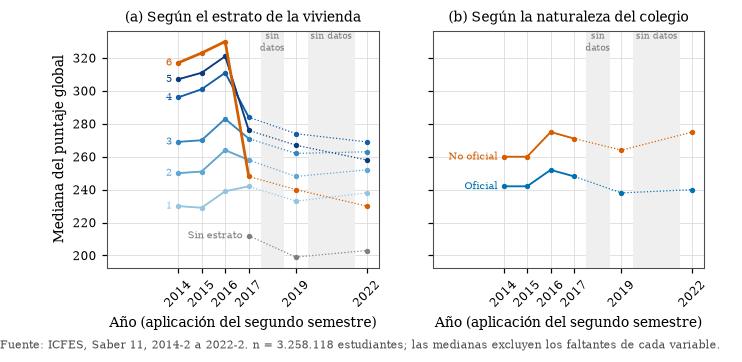

In [24]:
ANIOS = range(2014, 2023)
ANIOS_SIN_DATOS = [anio for anio in ANIOS if anio not in ANIO_PERIODO.values()]
colores_estrato = dict(zip(ORDEN_ESTRATO[:5], mpl.colormaps["Blues"](np.linspace(0.4, 0.95, 5))))
colores_estrato |= {"Estrato 6": PALETA_CATEGORICA[1], "Sin Estrato": COLOR_APOYO}
colores_naturaleza = {"OFICIAL": COLOR_OFICIAL, "NO OFICIAL": COLOR_NO_OFICIAL}


def dibujar_serie(eje: plt.Axes, medianas: pd.DataFrame, colores: dict, etiquetas: dict, destacada: str) -> None:
    """Una línea por categoría; punteada entre periodos separados por un hueco, continua entre años seguidos."""
    for anio in ANIOS_SIN_DATOS:
        eje.axvspan(anio - 0.5, anio + 0.5, color="#EFEFEF", linewidth=0)
    for categoria in medianas.columns:
        valores = medianas[categoria].dropna().rename(index=ANIO_PERIODO)
        estilo = "--" if categoria == "Sin Estrato" else "-"
        grosor = 1.8 if categoria == destacada else 1.2
        eje.plot(valores.index, valores.values, linestyle=":", color=colores[categoria], linewidth=0.8)
        consecutivos = valores.reindex(ANIOS)
        eje.plot(consecutivos.index, consecutivos.values, linestyle=estilo, color=colores[categoria], linewidth=grosor, marker="o", markersize=2.5)
        eje.annotate(etiquetas[categoria], (valores.index[0], valores.iloc[0]), xytext=(-4, 0), textcoords="offset points", ha="right", va="center", fontsize=6.5, color=colores[categoria])
    eje.set_xlim(2011.0, 2022.5)
    eje.set_xticks(list(ANIO_PERIODO.values()))
    eje.tick_params(axis="x", rotation=45)
    eje.set_xlabel("Año (aplicación del segundo semestre)")


figura, (eje_e, eje_n) = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=True)
dibujar_serie(eje_e, mediana_serie_estrato, colores_estrato, {e: ETIQUETA_ESTRATO[e].replace("\n", " ") for e in ORDEN_ESTRATO}, "Estrato 6")
dibujar_serie(eje_n, mediana_serie_naturaleza, colores_naturaleza, {"OFICIAL": "Oficial", "NO OFICIAL": "No oficial"}, "")
eje_e.set_ylabel("Mediana del puntaje global")
eje_e.set_title("(a) Según el estrato de la vivienda")
eje_n.set_title("(b) Según la naturaleza del colegio")
for eje in (eje_e, eje_n):
    eje.text(2018, eje.get_ylim()[1], "sin\ndatos", ha="center", va="top", fontsize=6, color="#7F7F7F")
    eje.text(2020.5, eje.get_ylim()[1], "sin datos", ha="center", va="top", fontsize=6, color="#7F7F7F")
anotar_fuente(eje_e, f"Fuente: ICFES, Saber 11, 2014-2 a 2022-2. n = {en_espanol(conteo['Publicadas'].sum())} estudiantes; las medianas excluyen los faltantes de cada variable.")
guardar_figura(figura, "serie-mediana")
plt.show()

**Lectura.** Entre 2014-2 y 2016-2 la mediana sube con el estrato sin excepción, y el estrato 6 encabeza la escalera. Desde 2017-2 el estrato 6 cae por debajo del 5 y del 4, y en 2022-2 queda incluso por debajo del 1. El cuadro del estrato 6 muestra dónde está el cambio: los estudiantes de estrato 6 en colegios oficiales se multiplican por dieciséis entre 2016-2 y 2017-2, mientras que los de colegios no oficiales cambian poco y conservan una mediana alta, y ese mismo año aparece la respuesta «Sin Estrato». Todo apunta a un cambio en la forma de registrar el estrato y no a un deterioro real del desempeño, aunque ningún documento del ICFES lo confirma, así que se trata como hipótesis. El panel (b) muestra que la brecha entre colegios oficiales y no oficiales se mantiene en todos los periodos.

## 8. Herramientas de visualización

### 8.1. El mismo gráfico en Matplotlib, Seaborn y Plotly

Las tres bibliotecas de Python dibujan los mismos dos gráficos con la misma especificación: el histograma del puntaje global del 2022-2 en intervalos de 10 puntos y el mapa de la correlación de Pearson entre los seis puntajes, este sin las cifras en las celdas, que ya muestra la sección 6.1, para que las cuatro versiones se lean a un cuarto del ancho de la página. Para cada una se mide el número de instrucciones de la función que construye el gráfico, el tiempo de construirlo y exportarlo a PNG (mediana de tres corridas), el peso del PNG y el de una segunda salida: el PDF vectorial en Matplotlib y Seaborn y el HTML interactivo en Plotly. El script `src/r/fase-1.R` hace la misma medición en ggplot2 y la deja en `resultados/r/fase-1.json`, de donde la toma la tabla; como ggplot2 encadena todo el gráfico en una sola expresión con `+`, el script cuenta también sus componentes (la llamada a `ggplot`, las capas, las escalas, las etiquetas y el tema). Los tiempos y pesos dependen de la máquina, por lo que sus macros llevan el prefijo `medida`.

[ok] Existe la salida del script de R (resultados/r/fase-1.json)


                         Instrucciones  Tiempo a PNG (s)  PNG (kB)    Segunda salida  Segunda salida (kB)
Gráfico     Herramienta                                                                                  
histograma  Matplotlib               6             0.055    32.887     PDF vectorial               12.112
            Seaborn                  5             0.118    34.316     PDF vectorial               12.142
            Plotly                   3             2.169    47.560  HTML interactivo             5556.762
            ggplot2                  1             0.191    28.657     PDF vectorial                4.773
correlacion Matplotlib               7             0.075    72.806     PDF vectorial               17.076
            Seaborn                  4             0.086    71.977     PDF vectorial               16.587
            Plotly                   3             1.897    74.734  HTML interactivo               10.052
            ggplot2                  3        

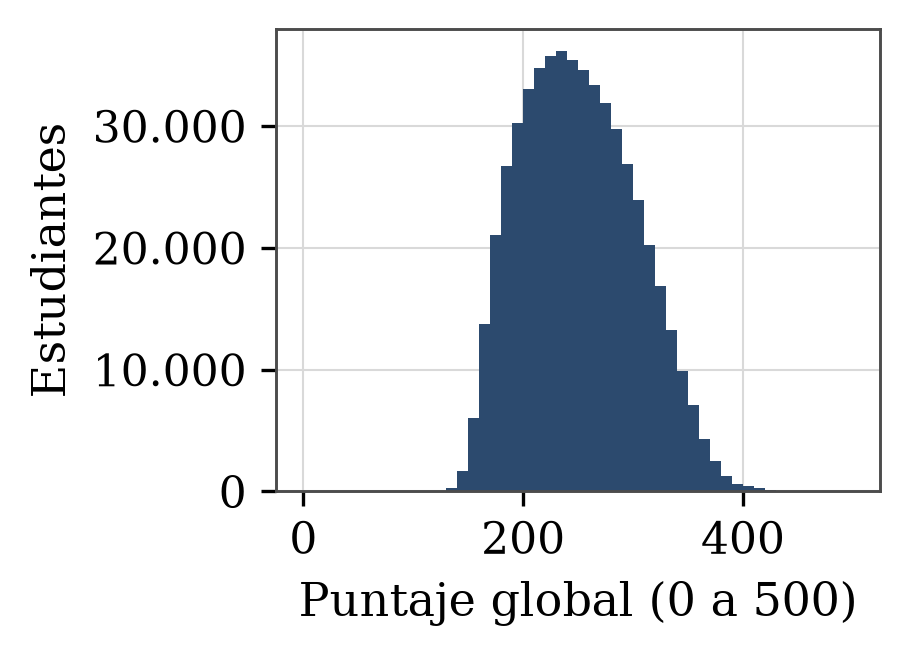

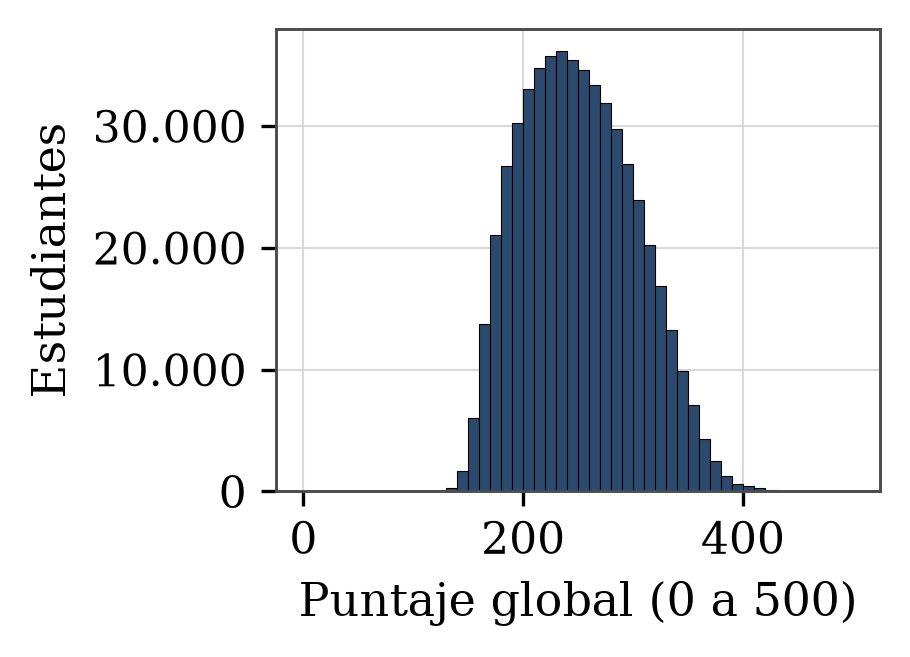

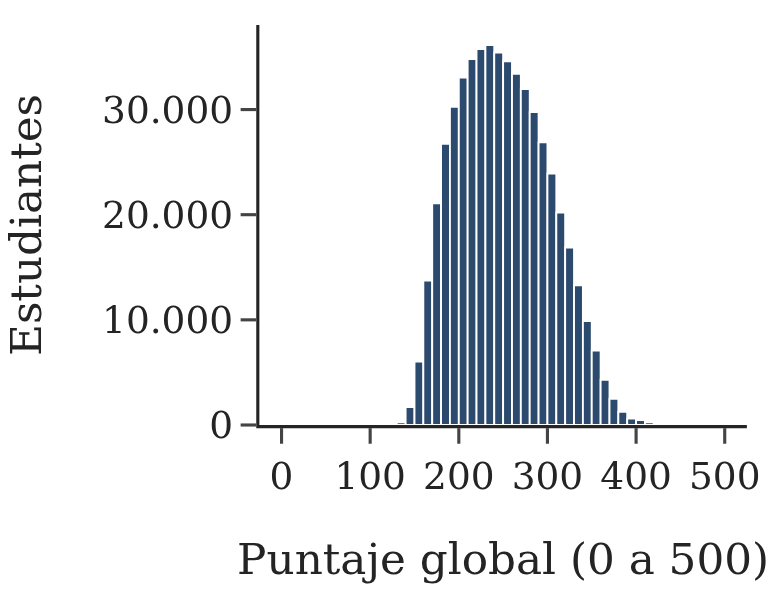

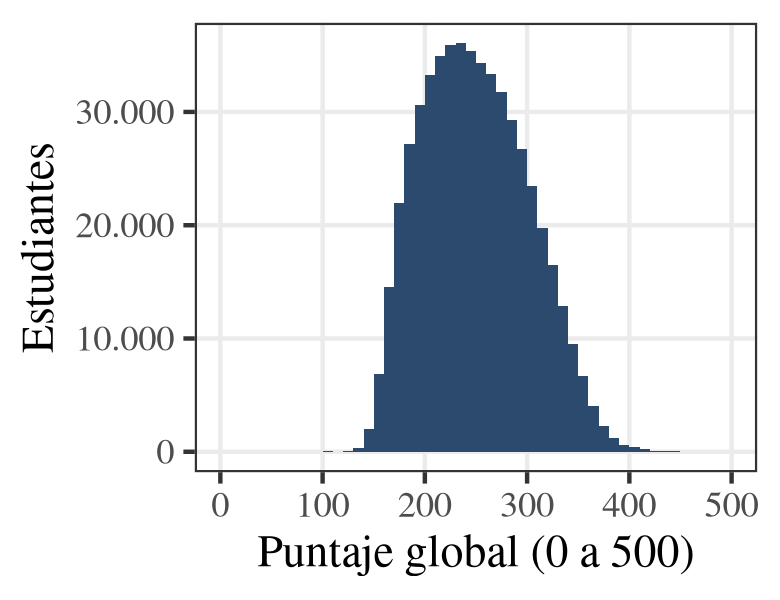

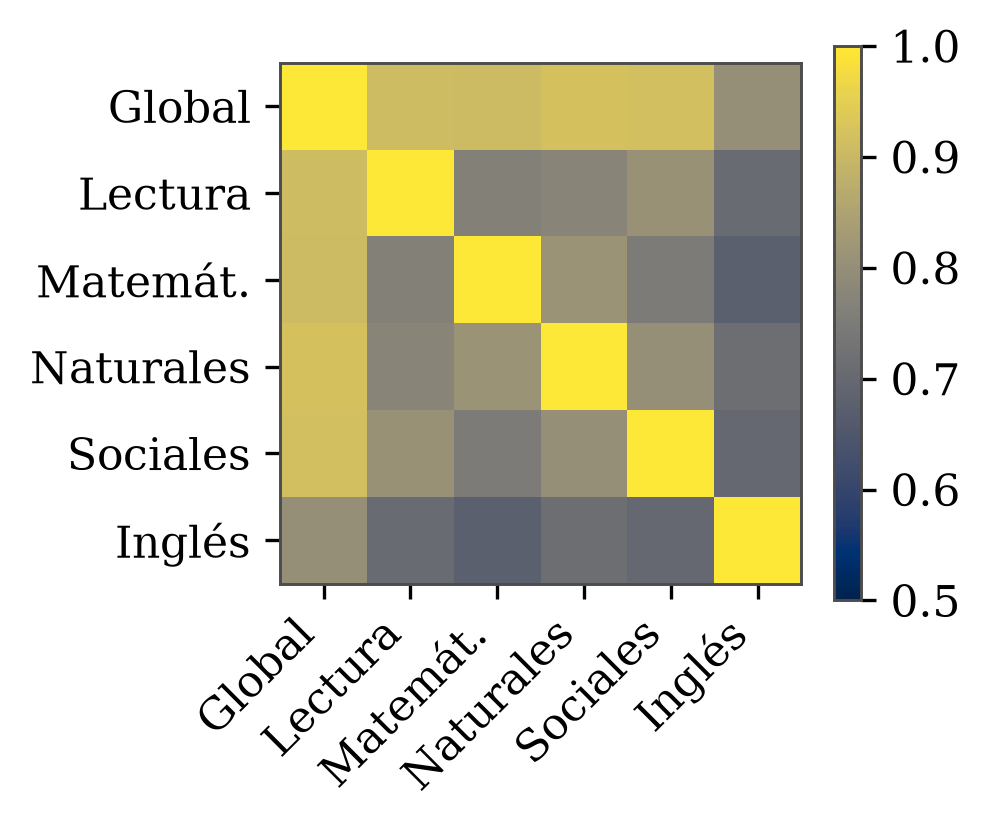

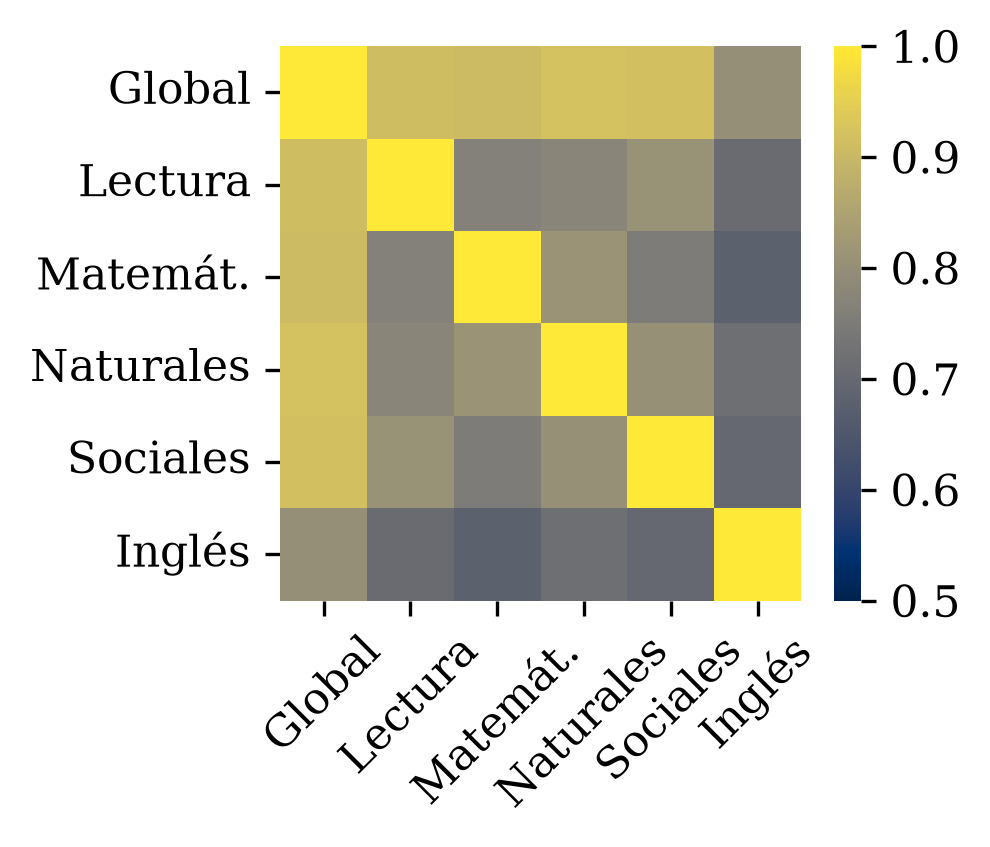

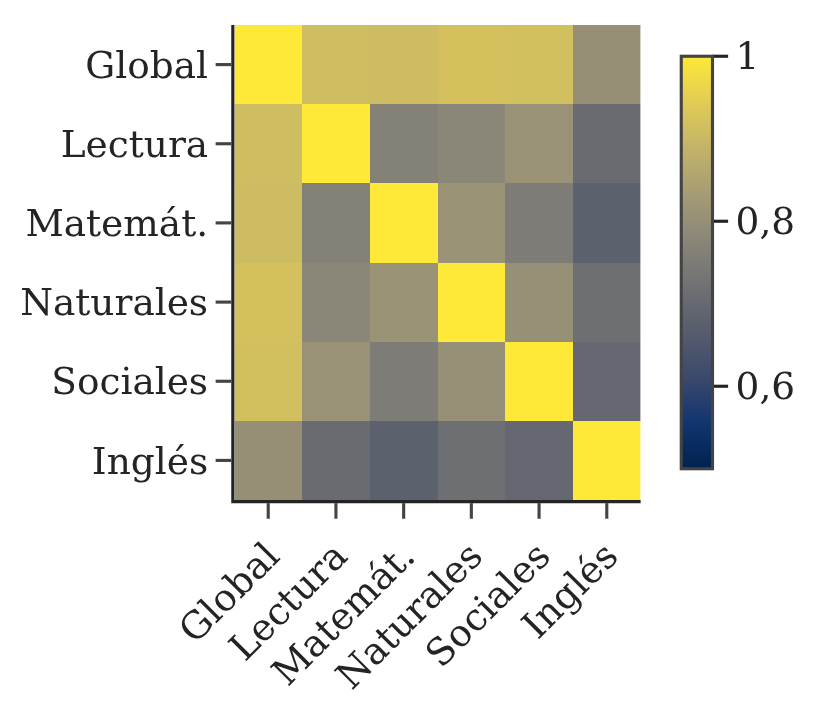

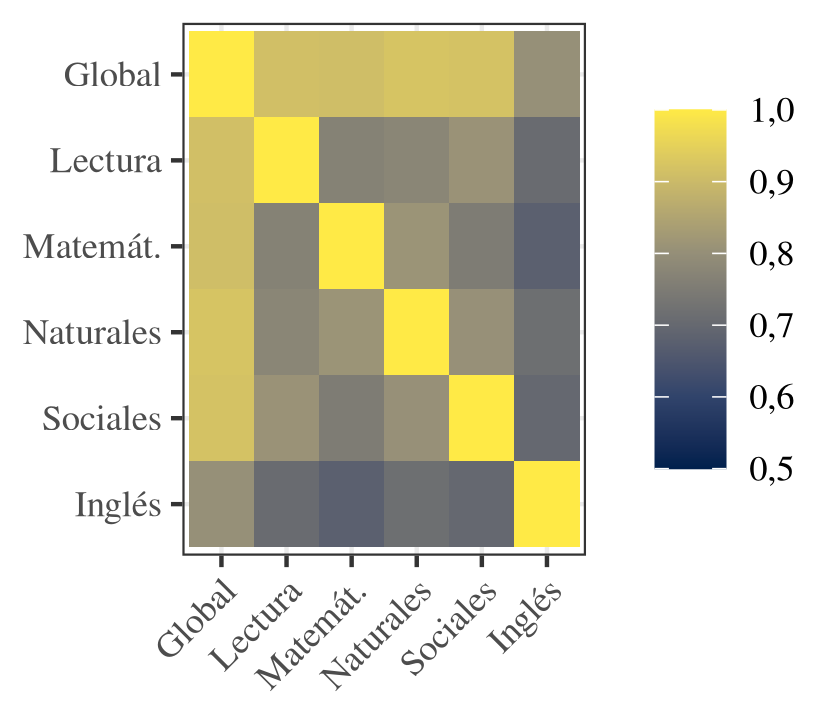

In [25]:
CORTES = np.arange(0, 510, 10)
TITULO_X = "Puntaje global (0 a 500)"
TITULO_Y = "Estudiantes"
TAMANO_HISTOGRAMA = (2.6, 2.0)
TAMANO_CORRELACION = (2.8, 2.4)
# El informe pone las ocho figuras de herramientas a un cuarto del ancho de la página, así que
# se dibujan con letra de 10 a 11 puntos para que impresas queden en unos 6 puntos. A ese
# tamaño las cifras dentro de las celdas no caben: los mapas de esta comparación van sin
# ellas, y la sección 6.1 muestra los valores.
ESTILO_HERRAMIENTAS = {"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5}
TAMANO_LETRA_PLOTLY = 12
PUNTOS_POR_PULGADA_PLOTLY = 96
ESCALA_PLOTLY = mpl.rcParams["savefig.dpi"] / PUNTOS_POR_PULGADA_PLOTLY


def histograma_matplotlib(puntajes: pd.Series) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_HISTOGRAMA)
    eje.hist(puntajes, bins=CORTES, color=COLOR_PRINCIPAL)
    eje.set_xlabel(TITULO_X)
    eje.set_ylabel(TITULO_Y)
    eje.yaxis.set_major_formatter(FORMATO_MILES)
    return figura


def histograma_seaborn(puntajes: pd.Series) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_HISTOGRAMA)
    sns.histplot(x=puntajes, bins=CORTES, color=COLOR_PRINCIPAL, alpha=1, ax=eje)
    eje.set(xlabel=TITULO_X, ylabel=TITULO_Y)
    eje.yaxis.set_major_formatter(FORMATO_MILES)
    return figura


def histograma_plotly(puntajes: pd.Series) -> go.Figure:
    figura = go.Figure(go.Histogram(x=puntajes, xbins={"start": 0, "end": 500, "size": 10}, marker_color=COLOR_PRINCIPAL))
    figura.update_layout(
        template="simple_white",
        width=TAMANO_HISTOGRAMA[0] * PUNTOS_POR_PULGADA_PLOTLY,
        height=TAMANO_HISTOGRAMA[1] * PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"title": TITULO_X, "range": [-25, 525], "dtick": 100, "tickangle": 0},
        yaxis={"title": TITULO_Y, "tickformat": ",d"},
        separators=",.",
        font={"family": "DejaVu Serif", "size": TAMANO_LETRA_PLOTLY},
        margin={"l": 62, "r": 8, "t": 8, "b": 45},
    )
    return figura


def correlacion_matplotlib(matriz: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_CORRELACION)
    imagen = eje.imshow(matriz.to_numpy(), cmap="cividis", vmin=MINIMO_ESCALA_CORRELACION, vmax=1)
    eje.set_xticks(range(len(etiquetas_cortas)), etiquetas_cortas, rotation=45, ha="right")
    eje.set_yticks(range(len(etiquetas_cortas)), etiquetas_cortas)
    eje.grid(False)
    figura.colorbar(imagen, ax=eje)
    return figura


def correlacion_seaborn(matriz: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_CORRELACION)
    sns.heatmap(matriz, vmin=MINIMO_ESCALA_CORRELACION, vmax=1, cmap="cividis", xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=eje)
    eje.tick_params(axis="x", rotation=45)
    return figura


def correlacion_plotly(matriz: pd.DataFrame) -> go.Figure:
    figura = go.Figure(go.Heatmap(z=matriz.to_numpy(), x=etiquetas_cortas, y=etiquetas_cortas, zmin=MINIMO_ESCALA_CORRELACION, zmax=1, colorscale="Cividis", colorbar={"thickness": 10, "tickfont": {"size": TAMANO_LETRA_PLOTLY}}))
    figura.update_layout(
        template="simple_white",
        width=TAMANO_CORRELACION[0] * PUNTOS_POR_PULGADA_PLOTLY,
        height=TAMANO_CORRELACION[1] * PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"tickangle": -45},
        yaxis={"autorange": "reversed"},
        separators=",.",
        font={"family": "DejaVu Serif", "size": TAMANO_LETRA_PLOTLY},
        margin={"l": 75, "r": 4, "t": 8, "b": 70},
    )
    return figura


GRAFICOS: dict[str, tuple[Callable[[], object], dict[str, Callable]]] = {
    "histograma": (lambda: puntaje, {"Matplotlib": histograma_matplotlib, "Seaborn": histograma_seaborn, "Plotly": histograma_plotly}),
    "correlacion": (lambda: pearson, {"Matplotlib": correlacion_matplotlib, "Seaborn": correlacion_seaborn, "Plotly": correlacion_plotly}),
}


def instrucciones(funcion: Callable) -> int:
    """Cuenta las instrucciones del cuerpo de la función, sin importar cómo se partan las líneas."""
    arbol = ast.parse(textwrap.dedent(inspect.getsource(funcion)))
    return len(arbol.body[0].body)


def exportar(figura, ruta: Path) -> None:
    """Exporta a PNG o PDF (Matplotlib) o a PNG o HTML (Plotly) y libera la figura."""
    if isinstance(figura, go.Figure):
        if ruta.suffix == ".html":
            figura.write_html(ruta, include_plotlyjs="cdn")
        else:
            figura.write_image(ruta, scale=ESCALA_PLOTLY)
    else:
        figura.savefig(ruta)
        plt.close(figura)


def medir(grafico: str, herramienta: str, repeticiones: int = 3) -> dict:
    datos_grafico, construir = GRAFICOS[grafico][0](), GRAFICOS[grafico][1][herramienta]
    ruta_png = RUTA_FIGURAS / f"herramientas-{grafico}-{herramienta.lower()}.png"
    tiempos = []
    with mpl.rc_context(ESTILO_HERRAMIENTAS):
        for _ in range(repeticiones):
            inicio = time.perf_counter()
            exportar(construir(datos_grafico), ruta_png)
            tiempos.append(time.perf_counter() - inicio)
        segunda = "HTML interactivo" if herramienta == "Plotly" else "PDF vectorial"
        with tempfile.TemporaryDirectory() as carpeta:
            ruta_segunda = Path(carpeta) / ("figura.html" if herramienta == "Plotly" else "figura.pdf")
            exportar(construir(datos_grafico), ruta_segunda)
            peso_segunda = ruta_segunda.stat().st_size / 1024
    FIGURAS_ESCRITAS.append(ruta_png)
    return {
        "Gráfico": grafico,
        "Herramienta": herramienta,
        "Instrucciones": instrucciones(construir),
        "Tiempo a PNG (s)": statistics.median(tiempos),
        "PNG (kB)": ruta_png.stat().st_size / 1024,
        "Segunda salida": segunda,
        "Segunda salida (kB)": peso_segunda,
    }


comprobar(f"Existe la salida del script de R ({relativa(RUTA_PARIDAD_R)})", RUTA_PARIDAD_R.is_file())
salida_r = json.loads(RUTA_PARIDAD_R.read_text(encoding="utf-8"))
RUTA_FIGURAS_R = RUTA_FIGURAS / "r"
filas_ggplot2 = [
    {
        "Gráfico": grafico,
        "Herramienta": "ggplot2",
        "Instrucciones": medida["instrucciones"],
        "Tiempo a PNG (s)": medida["tiempo_s"],
        "PNG (kB)": medida["png_kb"],
        "Segunda salida": "PDF vectorial",
        "Segunda salida (kB)": medida["pdf_kb"],
    }
    for grafico, medida in salida_r["medicion"].items()
]
filas_python = [medir(grafico, herramienta) for grafico, (_, funciones) in GRAFICOS.items() for herramienta in funciones]
medicion = pd.DataFrame(filas_python + filas_ggplot2).set_index(["Gráfico", "Herramienta"]).loc[list(GRAFICOS)]
print(medicion.round(3).to_string())
for grafico, medida in salida_r["medicion"].items():
    print(f"ggplot2 ({grafico}): {medida['componentes']} componentes encadenados con + en {medida['instrucciones']} instrucción(es)")

SUFIJO_HERRAMIENTA = {"Matplotlib": "Matplotlib", "Seaborn": "Seaborn", "Plotly": "Plotly", "ggplot2": "Ggplot"}
for (grafico, herramienta), fila in medicion.iterrows():
    sufijo = ("Hist" if grafico == "histograma" else "Corr") + SUFIJO_HERRAMIENTA[herramienta]
    cifra(f"medidaInstrucciones{sufijo}", fila["Instrucciones"])
    cifra(f"medidaTiempo{sufijo}", fila["Tiempo a PNG (s)"], 2)
    cifra(f"medidaPng{sufijo}", fila["PNG (kB)"], 0)
    cifra(f"medidaSegunda{sufijo}", fila["Segunda salida (kB)"], 0)
for grafico, medida in salida_r["medicion"].items():
    cifra(f"medidaComponentes{'Hist' if grafico == 'histograma' else 'Corr'}Ggplot", medida["componentes"])

for grafico in GRAFICOS:
    for herramienta in GRAFICOS[grafico][1]:
        display(Image(filename=RUTA_FIGURAS / f"herramientas-{grafico}-{herramienta.lower()}.png", width=300))
    display(Image(filename=RUTA_FIGURAS_R / f"herramientas-{grafico}-ggplot2.png", width=300))

**Lectura.** Las cuatro herramientas llegan al mismo gráfico, y sus diferencias están en el estilo por defecto, en la forma de escribir el código y en el costo de la salida. ggplot2 describe el gráfico como una suma de componentes, de modo que su conteo de instrucciones no es comparable con el de las bibliotecas de Python; el de componentes se parece al de Matplotlib. Seaborn traza un borde en cada barra, y Plotly abrevia los miles con el sufijo «k» si no se le indica el separador del español. Matplotlib y Seaborn construyen y exportan cada figura en fracciones de segundo y su PDF vectorial es liviano; Plotly necesita segundos para el PNG porque lanza un navegador sin interfaz a través de Kaleido, y su HTML del histograma incrusta todos los puntajes para recalcular las barras en el navegador. En un informe impreso esa interactividad no se aprovecha y su costo sí se paga.

### 8.2. La arquitectura de Matplotlib en un gráfico

Matplotlib organiza cada gráfico en tres capas: la capa de *backend*, que dibuja en un formato o en una pantalla; la capa de *artistas*, donde todo lo visible es un objeto `Artist`; y la capa de *scripting* de `pyplot`. Dentro de la capa de artistas la jerarquía es fija: una `Figure` contiene uno o más `Axes`, y cada `Axes` contiene los artistas primitivos (rectángulos, líneas, textos). La celda recorre esa jerarquía en el histograma de la sección anterior y muestra además que el método `plot` de pandas devuelve un `Axes` de Matplotlib, es decir, que pandas grafica a través de Matplotlib.

In [26]:
figura = histograma_matplotlib(puntaje)
eje = figura.axes[0]
rectangulos = [a for a in eje.get_children() if isinstance(a, mpl.patches.Rectangle) and a is not eje.patch]
print(f"Backend en uso: {mpl.get_backend()}")
print(f"Figure: {type(figura).__module__}.{type(figura).__name__}, {len(figura.axes)} Axes")
print(f"Axes: {type(eje).__module__}.{type(eje).__name__}")
print(f"  ejes (Axis): {type(eje.xaxis).__name__} y {type(eje.yaxis).__name__}")
print(f"  artistas hijos: {len(eje.get_children())}, de ellos {len(rectangulos)} rectángulos (una barra por intervalo)")
print(f"  títulos de los ejes (Text): {eje.xaxis.label.get_text()!r} y {eje.yaxis.label.get_text()!r}")
plt.close(figura)

eje_pandas = puntaje.plot.hist(bins=CORTES, figsize=TAMANO_HISTOGRAMA, color=COLOR_PRINCIPAL)
print(f"\nDataFrame.plot devuelve: {type(eje_pandas).__module__}.{type(eje_pandas).__name__}")
plt.close(eje_pandas.figure)
comprobar("El histograma de Matplotlib tiene una barra por cada intervalo de 10 puntos", len(rectangulos) == len(CORTES) - 1)
comprobar("pandas grafica a través de Matplotlib", isinstance(eje_pandas, mpl.axes.Axes))
cifra("barrasHistograma", len(rectangulos))

Backend en uso: module://matplotlib_inline.backend_inline
Figure: matplotlib.figure.Figure, 1 Axes
Axes: matplotlib.axes._axes.Axes
  ejes (Axis): XAxis y YAxis
  artistas hijos: 60, de ellos 50 rectángulos (una barra por intervalo)
  títulos de los ejes (Text): 'Puntaje global (0 a 500)' y 'Estudiantes'

DataFrame.plot devuelve: matplotlib.axes._axes.Axes
[ok] El histograma de Matplotlib tiene una barra por cada intervalo de 10 puntos
[ok] pandas grafica a través de Matplotlib


'50'

### 8.3. Comparación cualitativa

La tabla resume las cinco herramientas que compara el informe. Matplotlib, Seaborn y Plotly se ejecutan en este cuaderno, ggplot2 en el script de R y Power BI entra como referencia, porque no tiene una versión libre que se pueda ejecutar desde el repositorio. Las licencias de las bibliotecas de Python se leen de los metadatos del paquete instalado.

In [27]:
def licencia(paquete: str) -> str:
    """Lee la licencia del paquete instalado: primero el campo SPDX, después los clasificadores."""
    datos_paquete = metadata(paquete)
    if datos_paquete.get("License-Expression"):
        return datos_paquete["License-Expression"]
    clasificadores = [c for c in datos_paquete.get_all("Classifier") or [] if c.startswith("License ::")]
    return clasificadores[0].split("::")[-1].strip() if clasificadores else "sin dato"


tabla_cualitativa = pd.DataFrame(
    [
        ["Matplotlib", "Python", "Imperativo: control de cada artista de la figura", "PNG, PDF, SVG", "Limitada", licencia("matplotlib")],
        ["Seaborn", "Python", "Declarativo y estadístico, sobre Matplotlib", "PNG, PDF, SVG", "No", licencia("seaborn")],
        ["Plotly", "Python, R, JavaScript", "Declarativo: la figura es un objeto JSON", "HTML; imagen con Kaleido", "Sí", licencia("plotly")],
        ["ggplot2", "R", "Gramática de gráficos por capas", "PNG, PDF, SVG", "No", salida_r["licencia_ggplot2"]],
        ["Power BI", "Sin código (DAX y M)", "Tableros interactivos", "Servicio en la nube y archivo .pbix", "Sí", "Propietaria (Microsoft)"],
    ],
    columns=["Herramienta", "Lenguaje", "Enfoque", "Salida", "Interactividad", "Licencia"],
).set_index("Herramienta")
with pd.option_context("display.width", 250):
    print(tabla_cualitativa.to_string())

                          Lenguaje                                           Enfoque                               Salida Interactividad                            Licencia
Herramienta                                                                                                                                                                 
Matplotlib                  Python  Imperativo: control de cada artista de la figura                        PNG, PDF, SVG       Limitada  Python Software Foundation License
Seaborn                     Python       Declarativo y estadístico, sobre Matplotlib                        PNG, PDF, SVG             No                         BSD License
Plotly       Python, R, JavaScript          Declarativo: la figura es un objeto JSON             HTML; imagen con Kaleido             Sí                                 MIT
ggplot2                          R                   Gramática de gráficos por capas                        PNG, PDF, SVG             N

## 9. Paridad con R

El script `src/r/fase-1.R` lee el mismo recorte con `nanoparquet` y calcula, con las mismas definiciones, los descriptivos de los seis puntajes, las frecuencias del estrato y de la naturaleza del colegio, las matrices de Pearson y de Spearman y las dos pruebas χ² de H4. Esta sección compara cada valor con el de Python. Los conteos tienen que ser idénticos; los estadísticos, diferir en menos de una millonésima relativa.

R 4.6.1 y ggplot2 4.0.3
              Valores  Conteos  Diferencia relativa máxima
Bloque                                                    
Descriptivos       84        6                1.412679e-14
Frecuencias        11       11                0.000000e+00
Correlación        73        1                5.766294e-12
χ²                 10        4                1.395672e-15

Las cinco diferencias más grandes:
     Bloque                          Valor   Python        R  Diferencia relativa
Correlación      spearman: Global y Ingles 0.791980 0.791980         5.766294e-12
Correlación      spearman: Ingles y Global 0.791980 0.791980         5.766294e-12
Correlación spearman: Matematicas y Ingles 0.679010 0.679010         5.757052e-12
Correlación spearman: Ingles y Matematicas 0.679010 0.679010         5.757052e-12
Correlación spearman: Global y Matematicas 0.909426 0.909426         5.719302e-12
[ok] Paridad con R: R leyó las mismas filas del 2022-2
[ok] Paridad con R: los conteos y las f

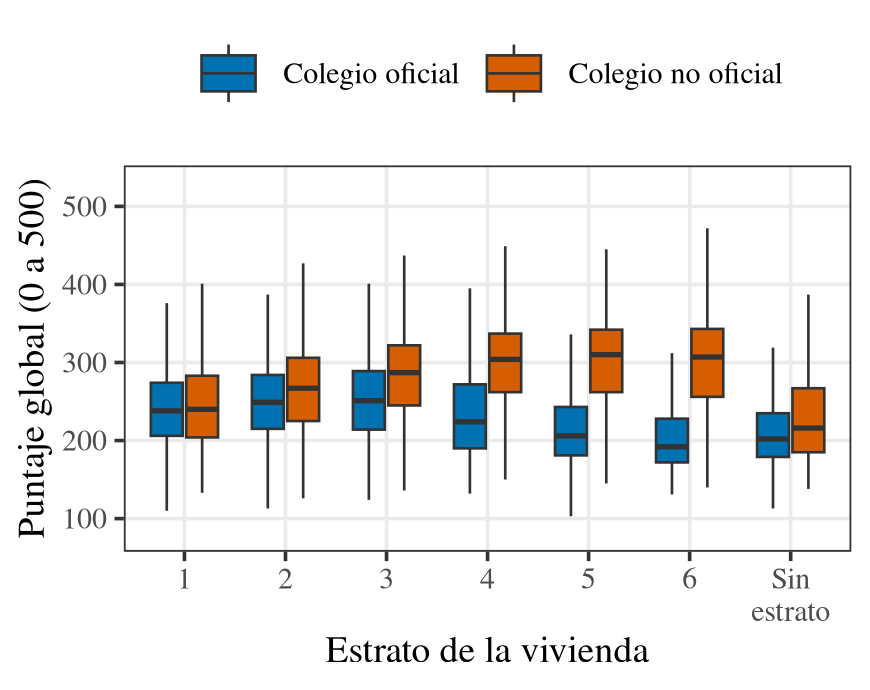

In [28]:
TOLERANCIA_PARIDAD = 1e-6
BLOQUES_PARIDAD = {"Descriptivos": "Descriptivos", "Frecuencias": "Frecuencias", "Correlación": "Correlacion", "χ²": "Chi"}


def diferencia_relativa(python: float, r: float) -> float:
    """Cero si los dos valores son iguales; si no, la diferencia sobre el mayor valor absoluto."""
    if python == r:
        return 0.0
    return abs(python - r) / max(abs(python), abs(r))


def filas_paridad() -> list[tuple[str, str, bool, float, float]]:
    """(bloque, valor, es conteo, Python, R) para cada valor que calcula el script de R."""
    filas = []
    for columna, medidas in salida_r["descriptivos"].items():
        for medida, valor_r in medidas.items():
            filas.append(("Descriptivos", f"{NOMBRE_PUNTAJE[columna]}: {medida}", medida == "n", tabla_descriptivos.loc[medida, columna], valor_r))
    for columna, conteos_r in salida_r["frecuencias"].items():
        for categoria, valor_r in conteos_r.items():
            filas.append(("Frecuencias", f"{columna}: {categoria}", True, tablas_frecuencia[columna].loc[categoria, "Estudiantes"], valor_r))
    filas.append(("Correlación", "estudiantes con los seis puntajes", True, len(completos), salida_r["correlacion"]["n"]))
    for metodo, matriz in (("pearson", pearson), ("spearman", spearman)):
        for fila, columnas in salida_r["correlacion"][metodo].items():
            for columna, valor_r in columnas.items():
                filas.append(("Correlación", f"{metodo}: {SUFIJO_PUNTAJE[fila]} y {SUFIJO_PUNTAJE[columna]}", False, matriz.loc[fila, columna], valor_r))
    for prueba, resultado_r in salida_r["chi2"].items():
        for medida, valor_r in resultado_r.items():
            filas.append(("χ²", f"{prueba}: {medida}", medida in ("n", "gl"), resultados_h4[prueba][medida], valor_r))
    return filas


paridad = pd.DataFrame(filas_paridad(), columns=["Bloque", "Valor", "Conteo", "Python", "R"])
paridad["Diferencia relativa"] = [diferencia_relativa(float(p), float(r)) for p, r in zip(paridad["Python"], paridad["R"])]
resumen_paridad = paridad.groupby("Bloque", sort=False).agg(Valores=("Valor", "size"), Conteos=("Conteo", "sum"), **{"Diferencia relativa máxima": ("Diferencia relativa", "max")})
print(f"R {salida_r['version_r']} y ggplot2 {salida_r['version_ggplot2']}")
print(resumen_paridad.to_string())
print("\nLas cinco diferencias más grandes:")
print(paridad.nlargest(5, "Diferencia relativa")[["Bloque", "Valor", "Python", "R", "Diferencia relativa"]].to_string(index=False))

comprobar("Paridad con R: R leyó las mismas filas del 2022-2", salida_r["descriptivos"]["PUNT_GLOBAL"]["n"] == len(actual))
comprobar("Paridad con R: los conteos y las frecuencias son idénticos", (paridad.loc[paridad["Conteo"], "Diferencia relativa"] == 0).all())
comprobar(f"Paridad con R: todos los estadísticos difieren en menos de {TOLERANCIA_PARIDAD:g} relativo", (paridad["Diferencia relativa"] < TOLERANCIA_PARIDAD).all())


def cota_decimal(valor: float) -> int:
    """Menor exponente k tal que el valor es menor que 10^k (-16 si es cero, la precisión doble)."""
    return int(np.floor(np.log10(valor))) + 1 if valor > 0 else -16


cifra("versionR", salida_r["version_r"])
cifra("versionGgplot", salida_r["version_ggplot2"])
cifra("paridadValores", len(paridad))
cifra("paridadConteos", int(paridad["Conteo"].sum()))
cifra("paridadCota", cota_decimal(paridad["Diferencia relativa"].max()))
for bloque, fila in resumen_paridad.iterrows():
    sufijo = BLOQUES_PARIDAD[bloque]
    cifra(f"paridadValores{sufijo}", fila["Valores"])
    cifra(f"paridadCota{sufijo}", cota_decimal(fila["Diferencia relativa máxima"]))
global_r = salida_r["descriptivos"]["PUNT_GLOBAL"]
cifra("rMediaGlobal", global_r["media"], 1)
cifra("rDesviacionGlobal", global_r["desviacion"], 1)
cifra("rAsimetriaGlobal", global_r["asimetria"], 3)
cifra("rCurtosisGlobal", global_r["curtosis"], 3)
for prueba, sufijo in (("estrato_naturaleza", "EstratoNaturaleza"), ("internet_zona", "InternetZona")):
    cifra(f"rChiDos{sufijo}", salida_r["chi2"][prueba]["estadistico"], 0)
    cifra(f"rVCramer{sufijo}", salida_r["chi2"][prueba]["v_cramer"], 3)

for nombre in ("herramientas-histograma-ggplot2", "herramientas-correlacion-ggplot2", "caja-estrato-naturaleza-ggplot2"):
    FIGURAS_ESCRITAS.append(RUTA_FIGURAS_R / f"{nombre}.png")
display(Image(filename=RUTA_FIGURAS_R / "caja-estrato-naturaleza-ggplot2.png", width=420))

**Lectura.** Python y R dan los mismos conteos y los mismos estadísticos: las diferencias que quedan están en las últimas cifras de la doble precisión y vienen del orden en que cada lenguaje suma. La paridad confirma que las definiciones coinciden (varianza muestral, cuartiles de tipo 7, asimetría sesgada, curtosis en exceso y χ² sin corrección de Yates), y deja el análisis replicable en los dos lenguajes que pide la actividad. La caja por estrato en ggplot2 reproduce el panel (b) de la sección 6.4.

## 10. Agregados para el tablero

El tablero de las fases siguientes lee estos dos archivos desde el repositorio, no los recortes con filas individuales. Ninguna celda se suprime: los agregados se diseñan para que todas tengan 10 o más estudiantes, porque una celda oculta se podría recuperar restando de los totales. Si alguna no llegara al mínimo, la comprobación detiene el cuaderno y la dimensión se agrupa. Las medidas se redondean a dos decimales.

In [29]:
agregado_departamento = (
    actual.dropna(subset=["COLE_COD_DEPTO_UBICACION"])
    .groupby("COLE_COD_DEPTO_UBICACION")
    .agg(
        departamento=("COLE_DEPTO_UBICACION", "first"),
        n=("PUNT_GLOBAL", "size"),
        media=("PUNT_GLOBAL", "mean"),
        mediana=("PUNT_GLOBAL", "median"),
        q1=("PUNT_GLOBAL", lambda s: s.quantile(0.25)),
        q3=("PUNT_GLOBAL", lambda s: s.quantile(0.75)),
        desviacion=("PUNT_GLOBAL", "std"),
    )
    .rename_axis("cod_depto")
    .reset_index()
)
AGREGADOS = {"serie-estrato-naturaleza.csv": agregado_serie, "departamento-20224.csv": agregado_departamento}
RUTA_AGREGADOS.mkdir(parents=True, exist_ok=True)
for nombre, tabla in AGREGADOS.items():
    comprobar(f"{nombre}: todas las celdas tienen {MINIMO_POR_CELDA} o más estudiantes", tabla["n"].min() >= MINIMO_POR_CELDA)
    tabla.round(2).to_csv(RUTA_AGREGADOS / nombre, index=False)
    print(f"Escrito {relativa(RUTA_AGREGADOS / nombre)}: {len(tabla)} celdas, la menor con {en_espanol(tabla['n'].min())} estudiantes")

comprobar("El agregado de la serie suma los estudiantes con estrato y naturaleza de los seis periodos", agregado_serie["n"].sum() == serie.filter(pl.col("FAMI_ESTRATOVIVIENDA").is_not_null() & pl.col("COLE_NATURALEZA").is_not_null()).select(pl.len()).collect().item())
comprobar("El agregado por departamento suma los estudiantes del 2022-2 con departamento", agregado_departamento["n"].sum() == actual["COLE_COD_DEPTO_UBICACION"].notna().sum())
cifra("celdasSerie", len(agregado_serie))
cifra("celdaMinimaSerie", agregado_serie["n"].min())
cifra("departamentos", len(agregado_departamento))
cifra("celdaMinimaDepartamento", agregado_departamento["n"].min())
mejor, peor = agregado_departamento.loc[agregado_departamento["mediana"].idxmax()], agregado_departamento.loc[agregado_departamento["mediana"].idxmin()]
print(f"Mediana departamental más alta: {mejor['departamento']} ({mejor['mediana']:.0f}); más baja: {peor['departamento']} ({peor['mediana']:.0f})")
cifra("medianaDeptoMaxima", mejor["mediana"], 0)
cifra("medianaDeptoMinima", peor["mediana"], 0)

[ok] serie-estrato-naturaleza.csv: todas las celdas tienen 10 o más estudiantes
Escrito data/agregados/serie-estrato-naturaleza.csv: 78 celdas, la menor con 106 estudiantes
[ok] departamento-20224.csv: todas las celdas tienen 10 o más estudiantes
Escrito data/agregados/departamento-20224.csv: 33 celdas, la menor con 389 estudiantes
[ok] El agregado de la serie suma los estudiantes con estrato y naturaleza de los seis periodos
[ok] El agregado por departamento suma los estudiantes del 2022-2 con departamento
Mediana departamental más alta: BOGOTÁ (270); más baja: CHOCO (197)


'197'

## 11. Cifras y comprobaciones

Las cifras registradas a lo largo del cuaderno se vuelcan a un JSON para el tablero y a un `.tex` con una macro por cifra para el informe; el volcado relee el `.tex` y falla si no coincide con el JSON. Después se comprueba que existan todas las figuras.

In [30]:
ruta_json, ruta_tex = cifras.volcar(RUTA_RESULTADOS, "cifras-fase-1")
print(f"{len(cifras)} cifras escritas en {relativa(ruta_json)} y {relativa(ruta_tex)}")
for ruta in FIGURAS_ESCRITAS:
    comprobar(f"Existe la figura {relativa(ruta)}", ruta.is_file())

print(f"\n{len(COMPROBACIONES)} de {len(COMPROBACIONES)} comprobaciones superadas.")

584 cifras escritas en resultados/cifras-fase-1.json y resultados/cifras-fase-1.tex
[ok] Existe la figura figuras/fase-1/faltantes.png
[ok] Existe la figura figuras/fase-1/histograma-global.png
[ok] Existe la figura figuras/fase-1/correlaciones.png
[ok] Existe la figura figuras/fase-1/hexbin-matematicas-lectura.png
[ok] Existe la figura figuras/fase-1/caja-estrato-naturaleza.png
[ok] Existe la figura figuras/fase-1/serie-mediana.png
[ok] Existe la figura figuras/fase-1/herramientas-histograma-matplotlib.png
[ok] Existe la figura figuras/fase-1/herramientas-histograma-seaborn.png
[ok] Existe la figura figuras/fase-1/herramientas-histograma-plotly.png
[ok] Existe la figura figuras/fase-1/herramientas-correlacion-matplotlib.png
[ok] Existe la figura figuras/fase-1/herramientas-correlacion-seaborn.png
[ok] Existe la figura figuras/fase-1/herramientas-correlacion-plotly.png
[ok] Existe la figura figuras/fase-1/r/herramientas-histograma-ggplot2.png
[ok] Existe la figura figuras/fase-1/r/herr